#0) Imports and Installs

In [1]:
!pip install yfinance

In [2]:
# IMPORTS
import numpy as np
import pandas as pd
import requests


#Fin Data Sources
import yfinance as yf
import pandas_datareader as pdr

#Data viz
import plotly.graph_objs as go
import plotly.express as px

import time
from datetime import date

# for graphs
import matplotlib.pyplot as plt

# 1) [Code Snippet 1] IPOs data from Web

* learn dataframes "stacking" (UNION ALL)
* learn about type casting
* generate new columns (simple and with function)


In [3]:
import pandas as pd
import requests
from io import StringIO

def get_ipos_by_year(year: int) -> pd.DataFrame:
    """
    Fetch IPO data for the given year from stockanalysis.com.
    """
    url = f"https://stockanalysis.com/ipos/{year}/"
    headers = {
        'User-Agent': (
            'Mozilla/5.0 (Windows NT 10.0; Win64; x64) '
            'AppleWebKit/537.36 (KHTML, like Gecko) '
            'Chrome/58.0.3029.110 Safari/537.3'
        )
    }

    try:
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()

        # Wrap HTML text in StringIO to avoid deprecation warning
        # "Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object."
        html_io = StringIO(response.text)
        tables = pd.read_html(html_io)

        if not tables:
            raise ValueError(f"No tables found for year {year}.")

        return tables[0]

    except requests.exceptions.RequestException as e:
        print(f"Request failed: {e}")
    except ValueError as ve:
        print(f"Data error: {ve}")
    except Exception as ex:
        print(f"Unexpected error: {ex}")

    return pd.DataFrame()

In [4]:
ipos_2023 = get_ipos_by_year(2023)
ipos_2023.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      154 non-null    object
 1   Symbol        154 non-null    object
 2   Company Name  154 non-null    object
 3   IPO Price     154 non-null    object
 4   Current       154 non-null    object
 5   Return        154 non-null    object
dtypes: object(6)
memory usage: 7.3+ KB


In [5]:
ipos_2024 = get_ipos_by_year(2024)
ipos_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      225 non-null    object
 1   Symbol        225 non-null    object
 2   Company Name  225 non-null    object
 3   IPO Price     225 non-null    object
 4   Current       225 non-null    object
 5   Return        225 non-null    object
dtypes: object(6)
memory usage: 10.7+ KB


In [6]:
ipos_2025 = get_ipos_by_year(2025)
ipos_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349 entries, 0 to 348
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      349 non-null    object
 1   Symbol        349 non-null    object
 2   Company Name  349 non-null    object
 3   IPO Price     349 non-null    object
 4   Current       349 non-null    object
 5   Return        349 non-null    object
dtypes: object(6)
memory usage: 16.5+ KB


In [7]:
ipos_2026 = get_ipos_by_year(2026)
ipos_2026.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      238 non-null    object
 1   Symbol        238 non-null    object
 2   Company Name  238 non-null    object
 3   IPO Price     238 non-null    object
 4   Current       238 non-null    object
 5   Return        238 non-null    object
dtypes: object(6)
memory usage: 11.3+ KB


In [8]:
# "stacking dataframes"
# pd.concat() is used to concatenate the DataFrames vertically.
# The ignore_index=True parameter ensures that the resulting DataFrame has a new index,
# ignoring the original indices of the input DataFrames.
# The stacked_df now contains the concatenated DataFrame.
stacked_ipos_df = pd.concat([ipos_2026 ,ipos_2025, ipos_2024, ipos_2023], ignore_index=True)

In [9]:
stacked_ipos_df.head(1)

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
0,"Sep 1, 2026",TLAC,Three Lions Acquisition Corp.,$10.00,$10.04,0.40%


In [10]:
# Need to convert everything to a proper type (date, str, int, float, etc.)
stacked_ipos_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 966 entries, 0 to 965
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   IPO Date      966 non-null    object
 1   Symbol        966 non-null    object
 2   Company Name  966 non-null    object
 3   IPO Price     966 non-null    object
 4   Current       966 non-null    object
 5   Return        966 non-null    object
dtypes: object(6)
memory usage: 45.4+ KB


In [11]:
# convert to datetime
stacked_ipos_df['IPO Date'] = pd.to_datetime(stacked_ipos_df['IPO Date'], format='mixed')

In [12]:
# Problem --> not always the columns are filled
missing_prices_df = stacked_ipos_df[stacked_ipos_df['IPO Price'].astype(str).str.find('-') >= 0]
missing_prices_df

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
69,2026-06-10,ATLQ,JAB Acquisition Corp I,-,$9.96,-
187,2026-02-11,IPXG,Inflection Point Acquisition Corp. VII,-,$10.05,-
273,2025-11-13,NXB,NextBoat Inc.,-,$2.21,-
350,2025-09-09,ZTG,Zenta Group Company Limited,-,$0.726,-
433,2025-06-17,MENS,Jyong Biotech Ltd.,-,$2.09,-
472,2025-05-07,CCAQ,Collective Acquisition Corp.,-,$10.70,-
505,2025-04-02,SORA,AsiaStrategy,-,$2.23,-
540,2025-02-21,MEDS,"DataMEDS AI, Inc.",-,$0.865,-
545,2025-02-13,IPEX,Inflection Point Acquisition Corp. V,-,$9.65,-
549,2025-02-12,PUSA,Aureus Greenway Holdings Inc.,-,$3.50,-


In [13]:
# it has some missing values --> use defensive errors='coerce' (if don't have time to crack into the data errors)
#     : pd.to_numeric() function call, which will convert problematic values to NaN.
#     otherwise you'll get a ValueError: Unable to parse string "-" at position 9
stacked_ipos_df['IPO Price'] = pd.to_numeric(stacked_ipos_df['IPO Price'].str.replace('$', ''), errors='coerce')
# not sure why, but need to call it again to transform 'object' to 'float64'
stacked_ipos_df['IPO Price'] = pd.to_numeric(stacked_ipos_df['IPO Price'])

In [14]:
# Convert "Current" column
stacked_ipos_df['Current'] = pd.to_numeric(stacked_ipos_df['Current'].str.replace('$', ''), errors='coerce')

# Convert 'Return' to numeric format (percentage)
stacked_ipos_df['Return'] = pd.to_numeric(stacked_ipos_df['Return'].str.replace('%', ''), errors='coerce') / 100

In [15]:
# Correctly applied transformations with 'defensive' techniques, but now not all are non-null
stacked_ipos_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 966 entries, 0 to 965
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   IPO Date      966 non-null    datetime64[ns]
 1   Symbol        966 non-null    object        
 2   Company Name  966 non-null    object        
 3   IPO Price     937 non-null    float64       
 4   Current       964 non-null    float64       
 5   Return        927 non-null    float64       
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 45.4+ KB


In [16]:
# simple way of checking NULLs
# (you need to understand how vector operations work .isnull() and calls chaining .isnull().sum())
stacked_ipos_df.isnull().sum()

,0
IPO Date,0
Symbol,0
Company Name,0
IPO Price,29
Current,2
Return,39


In [17]:
# Do you want to leave the record or not?
stacked_ipos_df[stacked_ipos_df.Return.isnull()]

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
69,2026-06-10,ATLQ,JAB Acquisition Corp I,NaN,9.960,NaN
88,2026-05-27,DGAC,Disciplined Growth Acquisition Corporation,10.0,10.000,NaN
171,2026-02-25,MZYX,MOZAYYX Acquisition Corp.,10.0,10.000,NaN
174,2026-02-19,AACO,Abony Acquisition Corp. I,10.0,10.000,NaN
183,2026-02-12,XFLH,XFLH Capital Corporation,10.0,10.000,NaN
187,2026-02-11,IPXG,Inflection Point Acquisition Corp. VII,NaN,10.050,NaN
222,2026-01-23,LEGO,Legato Merger Corp. IV,10.0,10.000,NaN
273,2025-11-13,NXB,NextBoat Inc.,NaN,2.210,NaN
304,2025-10-15,TCGL,TechCreate Group Ltd.,4.0,172.840,NaN
350,2025-09-09,ZTG,Zenta Group Company Limited,NaN,0.726,NaN


In [18]:
# now you can operate with columns as a numeric type
stacked_ipos_df['IPO Price'].mean()

np.float64(11.949252934898613)

In [19]:
# generate a new field -- SIMPLE calculation (no function needed)
stacked_ipos_df['Price Increase'] = stacked_ipos_df['Current'] - stacked_ipos_df['IPO Price']
stacked_ipos_df['Price Increase'].mean()

np.float64(2.08087486631016)

In [20]:
stacked_ipos_df.head(1)

,IPO Date,Symbol,Company Name,IPO Price,Current,Return,Price Increase
0,2026-09-01,TLAC,Three Lions Acquisition Corp.,10.0,10.04,0.004,0.04


In [21]:
# Descriptive Analytics of a dataset
stacked_ipos_df.describe()

,IPO Date,IPO Price,Current,Return,Price Increase
count,966,937.000000,964.000000,927.000000,935.000000
mean,2025-02-27 13:36:53.664596224,11.949253,13.769030,0.029989,2.080875
min,2023-01-13 00:00:00,2.500000,0.002000,-0.999500,-45.970000
25%,2024-06-18 18:00:00,5.000000,2.910000,-0.504650,-3.059500
50%,2025-04-29 00:00:00,10.000000,10.050000,-0.000200,0.000000
75%,2025-12-18 00:00:00,14.000000,11.912500,0.086900,0.835000
max,2026-09-01 00:00:00,185.000000,261.000000,8.862500,225.000000
std,NaN,12.181552,22.097392,0.946982,17.472817


In [22]:
# some visualisation: bar chart using Plotly Express
import plotly.express as px

# Truncate to the first day in the month - for Bar names
stacked_ipos_df['Date_monthly'] = stacked_ipos_df['IPO Date'].dt.to_period('M').dt.to_timestamp()

# Count the number of deals for each month and year
monthly_deals = stacked_ipos_df['Date_monthly'].value_counts().reset_index().sort_values(by='Date_monthly')
monthly_deals.columns = ['Date_monthly', 'Number of Deals']

# Plotting the bar chart using Plotly Express
fig = px.bar(monthly_deals,
             x='Date_monthly',
             y='Number of Deals',
             labels={'Month_Year': 'Month and Year', 'Number of Deals': 'Number of Deals'},
             title='Number of IPO Deals per Month and Year',
             text='Number of Deals'
             )
fig.update_traces(textposition='outside', # Position the text outside the bars
                  textfont=dict(color='black',size=14), # Adjust the font size of the text
                  )
fig.update_layout(title_x=0.5) # Center the title

fig.show()

In [23]:
rddt_filter = stacked_ipos_df.Symbol=='RDDT'
stacked_ipos_df[rddt_filter]

,IPO Date,Symbol,Company Name,IPO Price,Current,Return,Price Increase,Date_monthly
776,2024-03-21,RDDT,"Reddit, Inc.",34.0,160.47,3.7759,126.47,2024-03-01


In [24]:
# To be used for home assignment: 'You can notice a bump in the price after the IPO? And after that the price goes down
# You're asked to design a simple strategy to buy and hold for X days (at 'Adj.Close' price, no fees)
# Find an optimal X between 1 and 30, that delivers you a MAX mean return on ALL 2023 IPOs?
# Write down the answer X (a number between 1 and 30)

# What is the distribution of other returns 25-50-75% quantiles? Compare mean and median returns for 2023 (median may be more robust),
  # are you losing money in 25% cases (if 25% quantile returns is < 0)
  # Try the same X for all deals in 2024.  How the mean return in 2024 (out of sample data) is different from 2023 data?

# REDDIT - recent IPO
# https://finance.yahoo.com/quote/RDDT/
ticker_obj = yf.Ticker("RDDT")
reddit = ticker_obj.history(period = "max", interval = "1d")

reddit.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-09 00:00:00-04:00,148.639999,149.214996,145.166000,146.440002,4820400,0.0,0.0
2026-09-10 00:00:00-04:00,146.339996,156.949997,144.800003,155.339996,5813400,0.0,0.0
2026-09-11 00:00:00-04:00,157.550003,159.500000,154.610001,157.770004,3192600,0.0,0.0
2026-09-14 00:00:00-04:00,160.000000,166.179993,157.110001,162.380005,4549600,0.0,0.0
2026-09-15 00:00:00-04:00,157.899994,164.160004,157.305298,160.300003,1124848,0.0,0.0


<Axes: title={'center': "Reddit's (RDDT) price after the IPO"}, xlabel='Date'>

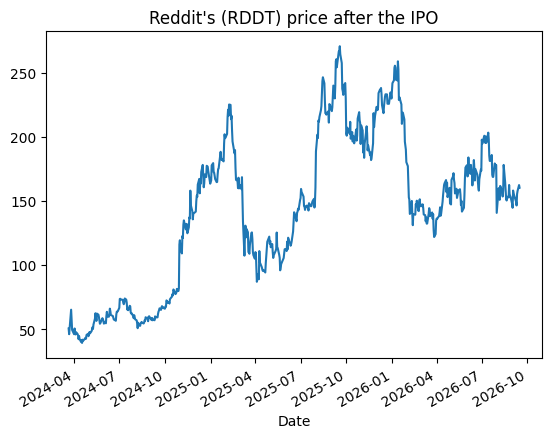

In [25]:
reddit['Close'].plot.line(title='Reddit\'s (RDDT) price after the IPO')

#2) OHLCV data transformations

## 2.1 [Code Snippet 2] Time series for OHLCV

In [26]:
ticker_obj = yf.Ticker("NVO")
nvo_df = ticker_obj.history(period = "max", interval = "1d")

In [27]:
# big plus of an API's data: good typing from the box!
# notice DatetimeIndex - it is a recognised date
nvo_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 11436 entries, 1981-04-30 00:00:00-04:00 to 2026-09-15 00:00:00-04:00
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          11436 non-null  float64
 1   High          11436 non-null  float64
 2   Low           11436 non-null  float64
 3   Close         11436 non-null  float64
 4   Volume        11436 non-null  int64  
 5   Dividends     11436 non-null  float64
 6   Stock Splits  11436 non-null  float64
dtypes: float64(6), int64(1)
memory usage: 714.8 KB


In [28]:
nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-09 00:00:00-04:00,45.000000,45.400002,44.520000,44.560001,8828000,0.0,0.0
2026-09-10 00:00:00-04:00,44.599998,44.820000,44.009998,44.009998,6580900,0.0,0.0
2026-09-11 00:00:00-04:00,43.200001,43.500000,42.720001,43.070000,11029100,0.0,0.0
2026-09-14 00:00:00-04:00,43.660000,43.709999,43.070000,43.450001,6555000,0.0,0.0
2026-09-15 00:00:00-04:00,42.724998,42.930000,42.535000,42.630001,1906075,0.0,0.0


In [29]:
# filter on date (index)
nvo_df_filtered_from_2020 = nvo_df[nvo_df.index>='2020-01-01']
nvo_df_filtered_from_2024 = nvo_df[nvo_df.index>='2024-01-01']

<Axes: title={'center': 'Novo Nordisk A/S (NVO) price daily'}, xlabel='Date'>

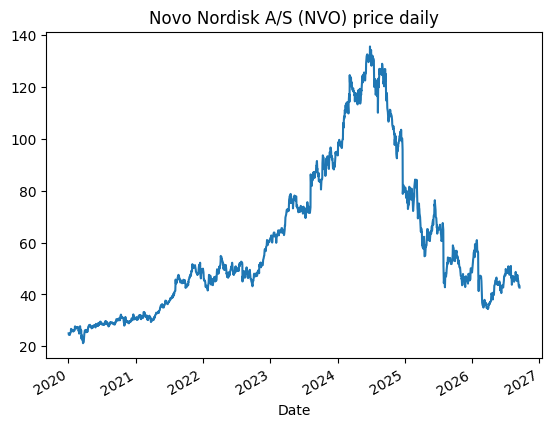

In [30]:
# Chaining: select one column, draw a plot, of a type line
nvo_df_filtered_from_2020['Close'].plot.line(title='Novo Nordisk A/S (NVO) price daily')

In [31]:
# generating new fields (using DateTime features):

nvo_df['Ticker'] = 'NVO'
nvo_df['Year']= nvo_df.index.year
nvo_df['Month'] = nvo_df.index.month
nvo_df['Weekday'] = nvo_df.index.weekday
nvo_df['Date'] = nvo_df.index.date # to be used in joins

In [32]:
nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,Weekday,Date
Date,,,,,,,,,,,,
2026-09-09 00:00:00-04:00,45.000000,45.400002,44.520000,44.560001,8828000,0.0,0.0,NVO,2026,9,2,2026-09-09
2026-09-10 00:00:00-04:00,44.599998,44.820000,44.009998,44.009998,6580900,0.0,0.0,NVO,2026,9,3,2026-09-10
2026-09-11 00:00:00-04:00,43.200001,43.500000,42.720001,43.070000,11029100,0.0,0.0,NVO,2026,9,4,2026-09-11
2026-09-14 00:00:00-04:00,43.660000,43.709999,43.070000,43.450001,6555000,0.0,0.0,NVO,2026,9,0,2026-09-14
2026-09-15 00:00:00-04:00,42.724998,42.930000,42.535000,42.630001,1906075,0.0,0.0,NVO,2026,9,1,2026-09-15


In [33]:
# shift ALL values (on x periods forward (+1) and backward (-1))
# equivalent of joining with a dataframe of the same vector, but with shifted date index
nvo_df['close_minus_1'] = nvo_df['Close'].shift(-1)
nvo_df['close_plus_1'] = nvo_df['Close'].shift(1)

nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,Weekday,Date,close_minus_1,close_plus_1
Date,,,,,,,,,,,,,,
2026-09-09 00:00:00-04:00,45.000000,45.400002,44.520000,44.560001,8828000,0.0,0.0,NVO,2026,9,2,2026-09-09,44.009998,45.160000
2026-09-10 00:00:00-04:00,44.599998,44.820000,44.009998,44.009998,6580900,0.0,0.0,NVO,2026,9,3,2026-09-10,43.070000,44.560001
2026-09-11 00:00:00-04:00,43.200001,43.500000,42.720001,43.070000,11029100,0.0,0.0,NVO,2026,9,4,2026-09-11,43.450001,44.009998
2026-09-14 00:00:00-04:00,43.660000,43.709999,43.070000,43.450001,6555000,0.0,0.0,NVO,2026,9,0,2026-09-14,42.630001,43.070000
2026-09-15 00:00:00-04:00,42.724998,42.930000,42.535000,42.630001,1906075,0.0,0.0,NVO,2026,9,1,2026-09-15,NaN,43.450001


In [34]:
# historical growth
nvo_df['growth_1d'] = nvo_df['Close'] / nvo_df['Close'].shift(1)           # nvo_df['close_plus_1']
nvo_df['growth_30d'] = nvo_df['Close'] / nvo_df['Close'].shift(30)

# FUTURE Growth : for regression models
nvo_df['growth_future_1d'] = nvo_df['Close'].shift(-1) / nvo_df['Close']   # nvo_df['close_minus_1']
nvo_df['growth_future_30d'] = nvo_df['Close'].shift(-30) / nvo_df['Close']   # nvo_df['close_minus_1']


# FUTURE Growth: for binary models
nvo_df['is_positive_growth_1d_future'] = np.where(nvo_df['growth_future_1d'] > 1, 1, 0)
nvo_df['is_positive_growth_30d_future'] = np.where(nvo_df['growth_future_30d'] > 1, 1, 0)


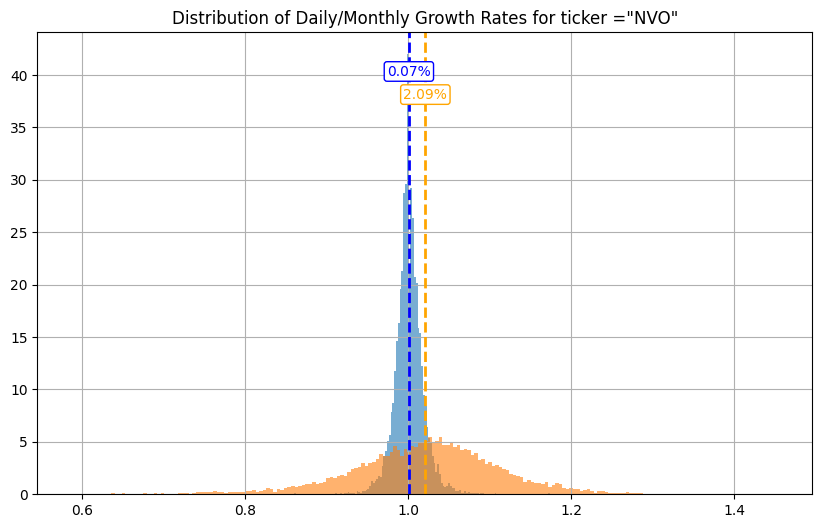

In [35]:
# normally the growth in 1 day is +-10%, while a lot of it is around 0% (around 1.)
plt.figure(figsize=(10, 6))
plt.title('Distribution of Daily/Monthly Growth Rates for ticker ="NVO"')

nvo_df.growth_1d.hist(bins=200, alpha=0.6, density=True)
nvo_df.growth_30d.hist(bins=200, alpha=0.6, density=True)

# Add vertical lines for averages
mean_1d = nvo_df.growth_1d.mean()
mean_30d = nvo_df.growth_30d.mean()

plt.axvline(mean_1d, color='blue', linestyle='--', linewidth=2, label=f'1d avg = {mean_1d:.3f}')
plt.axvline(mean_30d, color='orange', linestyle='--', linewidth=2, label=f'30d avg = {mean_30d:.3f}')


# Add mean text labels (as percent change)
ymax = plt.ylim()[1]
plt.text(mean_1d, ymax * 0.90,
         f'{(mean_1d - 1) * 100:.2f}%',
         color='blue', ha='center', va='bottom',
         bbox=dict(facecolor='white', edgecolor='blue', boxstyle='round,pad=0.2'))

plt.text(mean_30d, ymax * 0.85,
         f'{(mean_30d - 1) * 100:.2f}%',
         color='orange', ha='center', va='bottom',
         bbox=dict(facecolor='white', edgecolor='orange', boxstyle='round,pad=0.2'))


plt.show()

<Axes: title={'center': 'Distribution of 2-days Growth Rates for ticker = "NVO"'}>

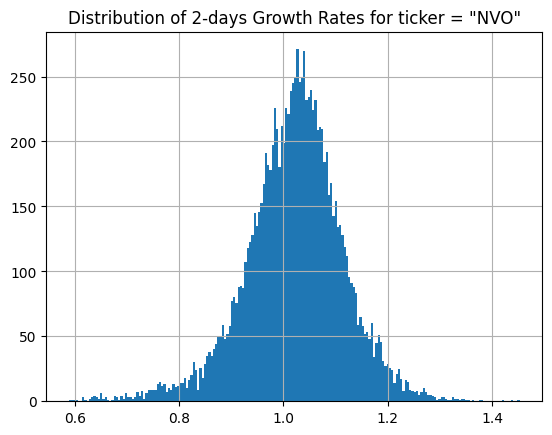

In [36]:
# you can see that the growth is can be much wider in 30 days (+- 30%)
plt.title('Distribution of 2-days Growth Rates for ticker = "NVO"')

nvo_df.growth_30d.hist(bins=200)

In [37]:
# for modeling: we use growth_1d, growth_2d as feature
COLUMNS = [k for k in nvo_df.keys() if k.find('growth')>=0 or k=='Close']
nvo_df[COLUMNS].tail()

,Close,growth_1d,growth_30d,growth_future_1d,growth_future_30d,is_positive_growth_1d_future,is_positive_growth_30d_future
Date,,,,,,,
2026-09-09 00:00:00-04:00,44.560001,0.986714,0.885585,0.987657,NaN,0,0
2026-09-10 00:00:00-04:00,44.009998,0.987657,0.864141,0.978641,NaN,0,0
2026-09-11 00:00:00-04:00,43.070000,0.978641,0.845192,1.008823,NaN,1,0
2026-09-14 00:00:00-04:00,43.450001,1.008823,0.934690,0.981128,NaN,0,0
2026-09-15 00:00:00-04:00,42.630001,0.981128,0.916856,NaN,NaN,0,0


In [38]:
# Calculate the distribution if future growth
nvo_df.is_positive_growth_1d_future.value_counts() / len(nvo_df)

,count
is_positive_growth_1d_future,
0,0.513116
1,0.486884


In [39]:
nvo_df.is_positive_growth_30d_future.value_counts() / len(nvo_df)

,count
is_positive_growth_30d_future,
1,0.616474
0,0.383526


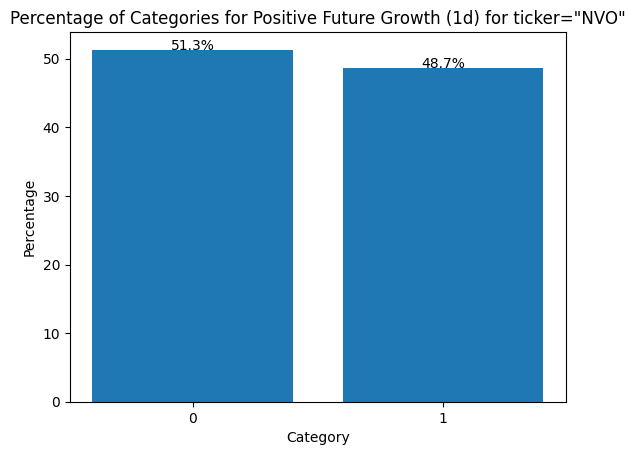

In [40]:
# Calculate value counts
value_counts = nvo_df['is_positive_growth_1d_future'].value_counts()

# Calculate percentage of each category
percentage = (value_counts / len(nvo_df)) * 100

# Plot as a bar chart
plt.bar(percentage.index.astype(str), percentage)
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.title('Percentage of Categories for Positive Future Growth (1d) for ticker="NVO"')

# Add percentage values on top of each bar
for i, value in enumerate(percentage):
    plt.text(i, value + 0, f'{value:.1f}%', ha='center')

plt.show()

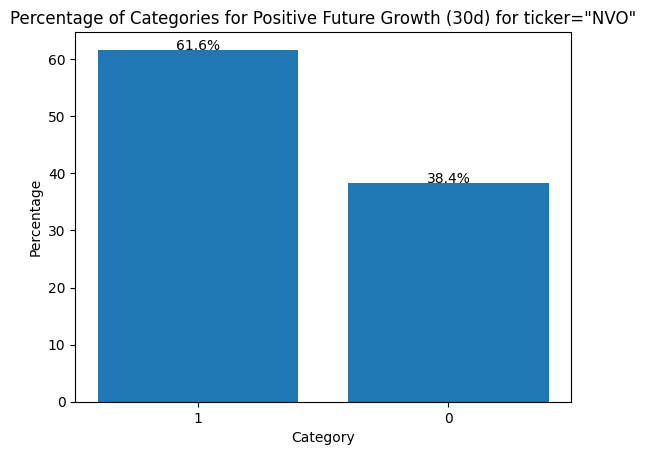

In [41]:
# Calculate value counts
value_counts = nvo_df['is_positive_growth_30d_future'].value_counts()

# Calculate percentage of each category
percentage = (value_counts / len(nvo_df)) * 100

# Plot as a bar chart
plt.bar(percentage.index.astype(str), percentage)
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.title('Percentage of Categories for Positive Future Growth (30d) for ticker="NVO"')

# Add percentage values on top of each bar
for i, value in enumerate(percentage):
    plt.text(i, value + 0, f'{value:.1f}%', ha='center')

plt.show()

## 2.2) [Code Snippet 6] Candlestick chart for OHLCV

In [42]:
# Candlestick charts : https://plotly.com/python/candlestick-charts/
import plotly.graph_objects as go

fig = go.Figure(data=[go.Candlestick(x=nvo_df_filtered_from_2020.index,
                open=nvo_df_filtered_from_2020.Open,
                high=nvo_df_filtered_from_2020.High,
                low=nvo_df_filtered_from_2020.Low,
                close=nvo_df_filtered_from_2020.Close)
               ])

fig.update_layout(
    title="NVO's daily candlestick chart from 2020",
    title_x=0.5,  # Set title x-position to center
    xaxis_rangeslider_visible=True
    )

fig.show()

# 3) Macro Indicators

## 3.0) Previous indicators from module 1

In [43]:
end = date.today()
print(f'Year = {end.year}; month= {end.month}; day={end.day}')

start = date(year=end.year-70, month=end.month, day=end.day)
print(f'Period for indexes: {start} to {end} ')

Year = 2026; month= 9; day=15
Period for indexes: 1956-09-15 to 2026-09-15 


In [44]:
# reuse code for ealier covered indicators
ticker_obj = yf.Ticker("^GDAXI")
dax_daily = ticker_obj.history(period = "max", interval = "1d")

In [45]:
for i in [1,3,7,30,90,365]:
  #DEBUG: dax_daily['Adj Close_sh_m_'+str(i)+'d'] = dax_daily['Adj Close'].shift(i)
  dax_daily['growth_dax_'+str(i)+'d'] = dax_daily['Close'] / dax_daily['Close'].shift(i)

In [46]:
dax_daily.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,,,,,,,,
1987-12-30 00:00:00+01:00,1005.190002,1005.190002,1005.190002,1005.190002,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1988-01-04 00:00:00+01:00,956.489990,956.489990,956.489990,956.489990,0,0.0,0.0,0.951551,NaN,NaN,NaN,NaN,NaN
1988-01-05 00:00:00+01:00,996.099976,996.099976,996.099976,996.099976,0,0.0,0.0,1.041412,NaN,NaN,NaN,NaN,NaN
1988-01-06 00:00:00+01:00,1006.010010,1006.010010,1006.010010,1006.010010,0,0.0,0.0,1.009949,1.000816,NaN,NaN,NaN,NaN
1988-01-07 00:00:00+01:00,1014.469971,1014.469971,1014.469971,1014.469971,0,0.0,0.0,1.008409,1.060617,NaN,NaN,NaN,NaN


In [47]:
dax_daily.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,,,,,,,,
2026-09-14 00:00:00+02:00,25498.740234,25548.779297,25325.519531,25440.810547,56050700,0.0,0.0,0.995004,0.994697,0.978368,0.978443,1.044785,1.232495
2026-09-15 00:00:00+02:00,25360.320312,25478.980469,25172.890625,25433.939453,0,0.0,0.0,0.999730,1.002870,0.976486,0.970674,1.061741,1.285216


In [48]:
GROWTH_KEYS = [k for k in dax_daily.keys() if k.startswith('growth')]
dax_daily_to_merge = dax_daily[GROWTH_KEYS]
dax_daily_to_merge.tail(1)

,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,
2026-09-15 00:00:00+02:00,0.99973,1.00287,0.976486,0.970674,1.061741,1.285216


In [49]:
def get_growth_df(df:pd.DataFrame, prefix:str)->pd.DataFrame:
  for i in [1,3,7,30,90,365]:
    df['growth_'+prefix+'_'+str(i)+'d'] = df['Close'] / df['Close'].shift(i)
    GROWTH_KEYS = [k for k in df.keys() if k.startswith('growth')]
  return df[GROWTH_KEYS]

In [50]:
# https://finance.yahoo.com/quote/%5EGSPC/
# SNP - SNP Real Time Price. Currency in USD
ticker_obj = yf.Ticker("^GSPC")

# snp500_daily = yf.download(tickers = "^GSPC",
#                      period = "max",
#                      interval = "1d")

snp500_daily = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [51]:
snp500_to_merge = get_growth_df(snp500_daily,'snp500')
snp500_to_merge.tail(2)

,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
Date,,,,,,
2026-09-14 00:00:00-04:00,0.995168,0.997855,0.993919,1.017392,1.049697,1.357837
2026-09-15 00:00:00-04:00,0.995281,0.998988,0.978872,0.997832,1.029721,1.346339


In [52]:
# Dow Jones Industrial Average: https://finance.yahoo.com/quote/%5EDJI?.tsrc=fin-srch

ticker_obj = yf.Ticker("^DJI")

# dji_daily = yf.download(tickers = "^DJI",
#                      period = "max",
#                      interval = "1d")


dji_daily = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [53]:
dji_daily_to_merge = get_growth_df(dji_daily,'dji')
dji_daily_to_merge.tail(2)

,growth_dji_1d,growth_dji_3d,growth_dji_7d,growth_dji_30d,growth_dji_90d,growth_dji_365d
Date,,,,,,
2026-09-14 00:00:00-04:00,0.997107,1.000774,0.987924,0.998784,1.063348,1.248071
2026-09-15 00:00:00-04:00,0.990202,0.996994,0.966872,0.976103,1.040012,1.236191


In [54]:
# ETFs
# WisdomTree India Earnings Fund (EPI)
# NYSEArca - Nasdaq Real Time Price. Currency in USD
# WEB: https://finance.yahoo.com/quote/EPI/history?p=EPI

# epi_etf_daily = yf.download(tickers = "EPI",
#                      period = "max",
#                      interval = "1d")

ticker_obj = yf.Ticker("EPI")
epi_etf_daily = ticker_obj.history(
                     period = "max",
                     interval = "1d")

epi_etf_daily.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,
2026-09-14 00:00:00-04:00,41.869999,42.259998,41.869999,42.150002,220900,0.0,0.0,0.0
2026-09-15 00:00:00-04:00,41.549999,41.570000,41.410000,41.424999,99457,0.0,0.0,0.0


In [55]:
epi_etf_daily_to_merge = get_growth_df(epi_etf_daily,'epi')
epi_etf_daily_to_merge.tail(2)

,growth_epi_1d,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d
Date,,,,,,
2026-09-14 00:00:00-04:00,0.996690,0.993167,0.971422,0.980461,0.974792,0.964310
2026-09-15 00:00:00-04:00,0.982799,0.986310,0.954273,0.957140,0.944052,0.952299


In [56]:
# Real Potential Gross Domestic Product (GDPPOT), Billions of Chained 2012 Dollars, QUARTERLY
# https://fred.stlouisfed.org/series/GDPPOT
gdppot = pdr.DataReader("GDPPOT", "fred", start=start)
gdppot['gdppot_us_yoy'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(4)-1
gdppot['gdppot_us_qoq'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(1)-1
gdppot.tail(2)

,GDPPOT,gdppot_us_yoy,gdppot_us_qoq
DATE,,,
2026-04-01,24070.938648,0.022185,0.005254
2026-07-01,24200.444694,0.021972,0.005380


In [57]:
gdppot_to_merge = gdppot[['gdppot_us_yoy','gdppot_us_qoq']]
gdppot_to_merge.tail(1)

,gdppot_us_yoy,gdppot_us_qoq
DATE,,
2026-07-01,0.021972,0.00538


In [58]:
# # "Core CPI index", MONTHLY
# https://fred.stlouisfed.org/series/CPILFESL
# The "Consumer Price Index for All Urban Consumers: All Items Less Food & Energy"
# is an aggregate of prices paid by urban consumers for a typical basket of goods, excluding food and energy.
# This measurement, known as "Core CPI," is widely used by economists because food and energy have very volatile prices.
cpilfesl = pdr.DataReader("CPILFESL", "fred", start=start)
cpilfesl['cpi_core_yoy'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(12)-1
cpilfesl['cpi_core_mom'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(1)-1

cpilfesl.tail(2)

,CPILFESL,cpi_core_yoy,cpi_core_mom
DATE,,,
2026-07-01,336.789,0.024665,0.002154
2026-08-01,337.765,0.024462,0.002898


In [59]:
cpilfesl_to_merge = cpilfesl[['cpi_core_yoy','cpi_core_mom']]
cpilfesl_to_merge.tail(2)

,cpi_core_yoy,cpi_core_mom
DATE,,
2026-07-01,0.024665,0.002154
2026-08-01,0.024462,0.002898


In [60]:
# Fed rate https://fred.stlouisfed.org/series/FEDFUNDS
fedfunds = pdr.DataReader("FEDFUNDS", "fred", start=start)
fedfunds.tail(2)

,FEDFUNDS
DATE,
2026-07-01,3.63
2026-08-01,3.63


In [61]:
# https://fred.stlouisfed.org/series/DGS1
dgs1 = pdr.DataReader("DGS1", "fred", start=start)
dgs1.tail(2)

,DGS1
DATE,
2026-09-10,4.28
2026-09-11,4.35


In [62]:
# https://fred.stlouisfed.org/series/DGS5
dgs5 = pdr.DataReader("DGS5", "fred", start=start)
dgs5.tail(2)

,DGS5
DATE,
2026-09-10,4.75
2026-09-11,4.78


In [63]:
# https://fred.stlouisfed.org/series/DGS10
dgs10 = pdr.DataReader("DGS10", "fred", start=start)
dgs10.tail(2)

,DGS10
DATE,
2026-09-10,4.95
2026-09-11,4.96


## 3.1) [Code snippet 3] VIX - Volatility Index

In [64]:
# VIX - Volatility Index
# https://finance.yahoo.com/quote/%5EVIX/

ticker_obj = yf.Ticker("^VIX")

# vix = yf.download(tickers = "^VIX",
#                      period = "max",
#                      interval = "1d")

vix = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [65]:
vix.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-14 00:00:00-05:00,17.50,18.170000,16.580000,17.100000,0,0.0,0.0
2026-09-15 00:00:00-05:00,17.57,18.030001,16.790001,17.469999,0,0.0,0.0


In [66]:
vix_to_merge = vix['Close']
vix_to_merge.tail()

,Close
Date,
2026-09-09 00:00:00-05:00,16.459999
2026-09-10 00:00:00-05:00,17.840000
2026-09-11 00:00:00-05:00,15.840000
2026-09-14 00:00:00-05:00,17.100000
2026-09-15 00:00:00-05:00,17.469999


<Axes: title={'center': 'VIX value over time'}, xlabel='Date'>

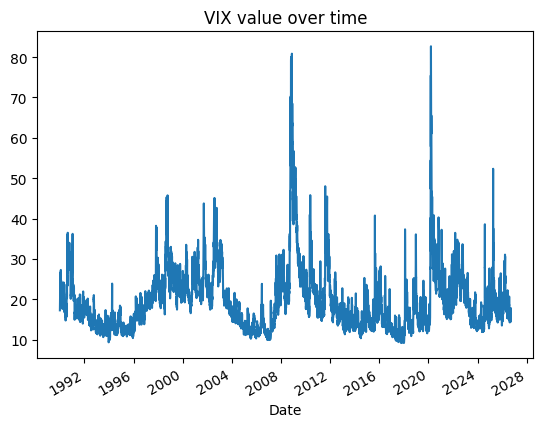

In [67]:
# Static graphs: hard to zoom in and get the exact dates of spikes
vix['Close'].plot.line(title = "VIX value over time")

In [68]:
# Dynamic visualisation of VIX prices
fig = px.line(vix,
              x=vix.index,
              y="Close",
              title='VIX over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

## 3.2) Gold - other assets

In [69]:
# GOLD
# WEB: https://finance.yahoo.com/quote/GC%3DF

ticker_obj = yf.Ticker("GC=F")

# gold = yf.download(tickers = "GC=F",
#                      period = "max",
#                      interval = "1d")

gold = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [70]:
gold.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-15 00:00:00-04:00,4340.299805,4358.200195,4301.600098,4324.299805,98211,0.0,0.0


In [71]:
gold_to_merge = get_growth_df(gold,'gold')
gold_to_merge.tail(2)

,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
Date,,,,,,
2026-09-14 00:00:00-04:00,0.987072,0.975609,0.985797,1.059630,0.952588,1.383312
2026-09-15 00:00:00-04:00,0.993658,0.981168,0.952510,1.057157,0.921181,1.365770


In [72]:
# Dynamic visualisation of GOLD prices
fig = px.line(gold,
              x=gold.index,
              y="Close",
              title='GOLD over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

## 3.3) WTI Crude and Brent Oil

In [73]:
# WTI Crude Oil
# WEB: https://uk.finance.yahoo.com/quote/CL=F/

ticker_obj = yf.Ticker("CL=F")

# crude_oil = yf.download(tickers = "CL=F",
#                      period = "max",
#                      interval = "1d")

crude_oil = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [74]:
crude_oil.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-14 00:00:00-04:00,102.250000,104.949997,100.529999,101.389999,399142,0.0,0.0
2026-09-15 00:00:00-04:00,102.010002,104.209999,101.209999,103.750000,180407,0.0,0.0


In [75]:
crude_oil_to_merge = get_growth_df(crude_oil,'wti_oil')
crude_oil_to_merge.tail(2)

,growth_wti_oil_1d,growth_wti_oil_3d,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d
Date,,,,,,
2026-09-14 00:00:00-04:00,1.013393,1.055596,1.114053,1.197473,0.991395,1.424017
2026-09-15 00:00:00-04:00,1.023276,1.012393,1.136364,1.291387,1.091186,1.446800


In [76]:
# Dynamic visualisation
fig = px.line(crude_oil,
              x=crude_oil.index,
              y="Close",
              title='WTI Crude Oil over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

In [77]:
# Brent Oil
# WEB: https://uk.finance.yahoo.com/quote/BZ=F/

ticker_obj = yf.Ticker("BZ=F")

# brent_oil = yf.download(tickers = "BZ=F",
#                      period = "max",
#                      interval = "1d")

brent_oil = ticker_obj.history(
                     period = "max",
                     interval = "1d")

brent_oil.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-14 00:00:00-04:00,106.889999,109.779999,104.82,105.680000,61285,0.0,0.0
2026-09-15 00:00:00-04:00,106.309998,103.139999,100.50,102.620003,25538,0.0,0.0


In [78]:
brent_oil_to_merge = get_growth_df(brent_oil,'brent_oil')
brent_oil_to_merge.tail(2)

,growth_brent_oil_1d,growth_brent_oil_3d,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d
Date,,,,,,
2026-09-14 00:00:00-04:00,1.010228,1.044166,1.105093,1.172659,0.961864,1.418714
2026-09-15 00:00:00-04:00,0.971045,0.953452,1.074330,1.225021,1.013331,1.369180


In [79]:
# Dynamic visualisation
fig = px.line(brent_oil,
              x=brent_oil.index,
              y="Close",
              title='Brent Oil over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()


## 3.4) Bitcoin prices: BTC_USD

In [80]:
# https://finance.yahoo.com/quote/BTC-USD/

ticker_obj = yf.Ticker("BTC-USD")

# btc_usd =  yf.download(tickers = "BTC-USD",
#                      period = "max",
#                      interval = "1d")


btc_usd =  ticker_obj.history(
                     period = "max",
                     interval = "1d")

btc_usd.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-14 00:00:00+00:00,76830.281250,79568.953125,76367.375000,78163.382812,29909358382,0.0,0.0
2026-09-15 00:00:00+00:00,78181.328125,78232.375000,76157.796875,76058.570312,30454700032,0.0,0.0


In [81]:
btc_usd_to_merge = get_growth_df(btc_usd,'btc_usd')
btc_usd_to_merge.tail(2)

,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
Date,,,,,,
2026-09-14 00:00:00+00:00,1.017247,1.012823,0.987961,1.240210,1.191503,0.677281
2026-09-15 00:00:00+00:00,0.973072,0.984316,0.969658,1.210764,1.180696,0.658830


In [82]:
# Dynamic visualisation
fig = px.line(btc_usd,
              x=btc_usd.index,
              y="Close",
              title='Bitcoin price daily')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()


## 3.5 [Code snippet 4] Eurostat: "The home of high-quality statistics and data on Europe"


In [83]:
!pip install eurostat

# https://pypi.org/project/eurostat/
# https://ec.europa.eu/eurostat/web/main/data/database

In [84]:
import eurostat

In [85]:
# LONG WAIT TIME ~15 min, unless you filter data

# https://ec.europa.eu/eurostat/cache/metadata/en/irt_euryld_esms.htm
  # Euro yield curves (irt_euryld)
  # Reference Metadata in Euro SDMX Metadata Structure (ESMS)
  # Compiling agency: Eurostat, the statistical office of the European Uni

# the service is slow, you need to specify addtional params : https://pypi.org/project/eurostat/0.2.3/

filter_pars = {'startPeriod':'2026-08-31', 'endPeriod':'2026-09-06'}

code = 'irt_euryld_d'
eurostat_euro_yield_df = eurostat.get_data_df(code, flags=True, filter_pars=filter_pars,  verbose=True)

Download progress: 100.0%



In [86]:
eurostat_euro_yield_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2148 entries, 0 to 2147
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   freq              2148 non-null   object 
 1   yld_curv          2148 non-null   object 
 2   maturity          2148 non-null   object 
 3   bonds             2148 non-null   object 
 4   geo\TIME_PERIOD   2148 non-null   object 
 5   2026-08-31_value  2148 non-null   float64
 6   2026-08-31_flag   2148 non-null   object 
 7   2026-09-01_value  2148 non-null   float64
 8   2026-09-01_flag   2148 non-null   object 
 9   2026-09-02_value  2148 non-null   float64
 10  2026-09-02_flag   2148 non-null   object 
 11  2026-09-03_value  2148 non-null   float64
 12  2026-09-03_flag   2148 non-null   object 
 13  2026-09-04_value  2148 non-null   float64
 14  2026-09-04_flag   2148 non-null   object 
dtypes: float64(5), object(10)
memory usage: 251.8+ KB


In [87]:
eurostat_euro_yield_df.head()

,freq,yld_curv,maturity,bonds,geo\TIME_PERIOD,2026-08-31_value,2026-08-31_flag,2026-09-01_value,2026-09-01_flag,2026-09-02_value,2026-09-02_flag,2026-09-03_value,2026-09-03_flag,2026-09-04_value,2026-09-04_flag
0,D,INS_FWD,M10,CGB_EA,EA,2.99586,,3.01466,,3.06000,,3.01606,,2.99200,
1,D,INS_FWD,M10,CGB_EA_AAA,EA,2.91537,,2.93919,,2.98761,,2.96601,,2.94878,
2,D,INS_FWD,M11,CGB_EA,EA,3.01626,,3.03579,,3.08304,,3.03717,,3.01120,
3,D,INS_FWD,M11,CGB_EA_AAA,EA,2.93753,,2.96217,,3.01071,,2.98697,,2.96960,
4,D,INS_FWD,M3,CGB_EA,EA,2.65833,,2.66916,,2.69979,,2.69313,,2.69038,


In [88]:
eurostat_euro_yield_df['bonds'].value_counts()

,count
bonds,
CGB_EA,1074
CGB_EA_AAA,1074


In [89]:
eurostat_euro_yield_df['maturity'].value_counts()


,count
maturity,
Y9_M9,6
M10,6
M11,6
M3,6
M4,6
...,...
Y10,6
Y1,6
M9,6


In [90]:
eurostat_euro_yield_df['yld_curv'].value_counts()

,count
yld_curv,
INS_FWD,716
PAR,716
SPOT_RT,716


In [91]:
eurostat_euro_yield_df

,freq,yld_curv,maturity,bonds,geo\TIME_PERIOD,2026-08-31_value,2026-08-31_flag,2026-09-01_value,2026-09-01_flag,2026-09-02_value,2026-09-02_flag,2026-09-03_value,2026-09-03_flag,2026-09-04_value,2026-09-04_flag
0,D,INS_FWD,M10,CGB_EA,EA,2.99586,,3.01466,,3.06000,,3.01606,,2.99200,
1,D,INS_FWD,M10,CGB_EA_AAA,EA,2.91537,,2.93919,,2.98761,,2.96601,,2.94878,
2,D,INS_FWD,M11,CGB_EA,EA,3.01626,,3.03579,,3.08304,,3.03717,,3.01120,
3,D,INS_FWD,M11,CGB_EA_AAA,EA,2.93753,,2.96217,,3.01071,,2.98697,,2.96960,
4,D,INS_FWD,M3,CGB_EA,EA,2.65833,,2.66916,,2.69979,,2.69313,,2.69038,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2143,D,SPOT_RT,Y9_M7,CGB_EA_AAA,EA,3.31259,,3.32831,,3.36502,,3.33722,,3.31958,
2144,D,SPOT_RT,Y9_M8,CGB_EA,EA,3.74107,,3.75831,,3.79659,,3.76034,,3.73914,
2145,D,SPOT_RT,Y9_M8,CGB_EA_AAA,EA,3.31804,,3.33373,,3.37044,,3.34276,,3.32502,
2146,D,SPOT_RT,Y9_M9,CGB_EA,EA,3.74834,,3.76556,,3.80375,,3.76752,,3.74633,


In [92]:
# Visual graph: https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_area_yield_curves/html/index.en.html
FILTER = (eurostat_euro_yield_df.yld_curv=='SPOT_RT')& (eurostat_euro_yield_df.bonds=='CGB_EA_AAA')
filtered_eurostat_euro_yield_df = eurostat_euro_yield_df[FILTER]

In [93]:
filtered_eurostat_euro_yield_df.sort_values(by='maturity')[['maturity','2026-09-01_value']].head(20)

,maturity,2026-09-01_value
1433,M10,2.68217
1435,M11,2.70662
1437,M3,2.42149
1439,M4,2.47067
1441,M5,2.51524
1443,M6,2.55561
1445,M7,2.59215
1447,M8,2.62522
1449,M9,2.65513
1451,Y1,2.72871


In [94]:
filtered_eurostat_euro_yield_df.sort_values(by='maturity')[['maturity','2026-09-01_value']].head(20)

,maturity,2026-09-01_value
1433,M10,2.68217
1435,M11,2.70662
1437,M3,2.42149
1439,M4,2.47067
1441,M5,2.51524
1443,M6,2.55561
1445,M7,2.59215
1447,M8,2.62522
1449,M9,2.65513
1451,Y1,2.72871


In [95]:
import re

def extract_numbers(input_string):
    y_match = re.search(r'Y(\d+)', input_string)
    m_match = re.search(r'M(\d+)', input_string)

    y_number = int(y_match.group(1)) if y_match else 0
    m_number = int(m_match.group(1)) if m_match else 0


    return y_number*12 + m_number

# Examples
examples = ["Y10_M2", "M3", "Y1"]
for example in examples:
    res = extract_numbers(example)
    print(f"{example} ==> {res}")

Y10_M2 ==> 122
M3 ==> 3
Y1 ==> 12


In [96]:
# define new field: "maturity in months"
filtered_eurostat_euro_yield_df.loc[:,'maturity_in_months'] = filtered_eurostat_euro_yield_df.maturity.apply(lambda x:extract_numbers(x))

/tmp/ipykernel_2783/4252248257.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [97]:
filtered_eurostat_euro_yield_df.sort_values(by='maturity_in_months')[['maturity','maturity_in_months','2026-09-01_value']].head(20)

,maturity,maturity_in_months,2026-09-01_value
1437,M3,3,2.42149
1439,M4,4,2.47067
1441,M5,5,2.51524
1443,M6,6,2.55561
1445,M7,7,2.59215
1447,M8,8,2.62522
1449,M9,9,2.65513
1433,M10,10,2.68217
1435,M11,11,2.70662
1451,Y1,12,2.72871


In [98]:
filtered_eurostat_euro_yield_df.loc[:,'maturity_in_years'] = filtered_eurostat_euro_yield_df.maturity_in_months/12.0

/tmp/ipykernel_2783/2163179308.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



<Axes: title={'center': 'AAA rated bonds spot yield curve'}, xlabel='maturity_in_years'>

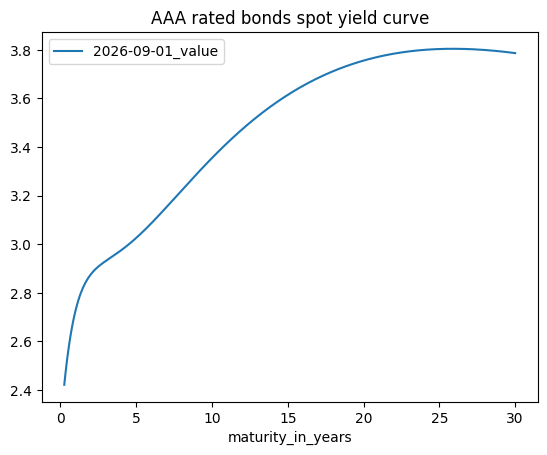

In [99]:
# exactly the same as on the Web:  https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_area_yield_curves/html/index.en.html
filtered_eurostat_euro_yield_df \
  .sort_values(by='maturity_in_months')[['maturity_in_years','2026-09-01_value']] \
  .plot.line(x='maturity_in_years',
            y='2026-09-01_value',
            title='AAA rated bonds spot yield curve')

# 4) [Code Snippet 5] Fundamental indicators

* Read about "Ratio Analysis" to learn about more ratios: https://www.investopedia.com/terms/r/ratioanalysis.asp
* https://algotrading101.com/learn/yahoo-finance-api-guide/

In [100]:
# let's select some set of stocks: e.g. top US companies on 'Employees':
# https://companiesmarketcap.com/usa/largest-american-companies-by-number-of-employees/

US_TOP_EMPLOYEES_STOCKS = ['WMT','AMZN','UPS','HD','CNXC','TGT','KR','UNH','BRK-B','SBUX']

# WMT
ticker = US_TOP_EMPLOYEES_STOCKS[0]

# WMT ticker
one_company = yf.Ticker(ticker)

In [101]:
# Fundamental info appears close earning dates, you need to download it and use quickly (before/after trading day),
#  unless you're a fundamental long-term investor looking for a several months-quarters-years strategy (period between buy and sell)
# This dfthis is the easiest thing to join with the main dataset and get "some" technical indicators present
# WMT ticker
eps_earnings = one_company.earnings_dates
eps_earnings['Ticker'] = ticker
eps_earnings

,EPS Estimate,Reported EPS,Surprise(%),Ticker
Earnings Date,,,,
2026-11-19 07:00:00-05:00,0.64,NaN,NaN,WMT
2026-08-20 06:00:00-04:00,0.74,0.81,9.27,WMT
2026-05-21 06:00:00-04:00,0.66,0.66,0.19,WMT
2026-02-19 06:00:00-05:00,0.73,0.74,1.79,WMT
2025-11-20 06:00:00-05:00,0.60,0.62,3.11,WMT
2025-08-21 06:00:00-04:00,0.74,0.68,-7.97,WMT
2025-05-15 06:00:00-04:00,0.58,0.61,5.64,WMT
2025-02-20 06:00:00-05:00,0.65,0.66,2.04,WMT
2024-11-19 06:00:00-05:00,0.53,0.58,8.84,WMT


In [102]:
one_company.calendar

{'Dividend Date': datetime.date(2027, 1, 4),
 'Ex-Dividend Date': datetime.date(2026, 12, 11),
 'Earnings Date': [datetime.date(2026, 11, 19)],
 'Earnings High': 0.67,
 'Earnings Low': 0.62,
 'Earnings Average': 0.63613,
 'Revenue High': 189775000000,
 'Revenue Low': 185556000000,
 'Revenue Average': 187195712010}

In [103]:
one_company.financials

,2026-01-31,2025-01-31,2024-01-31,2023-01-31,2022-01-31
Tax Effect Of Unusual Items,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
Tax Rate For Calcs,2.442910e-01,2.338360e-01,2.550000e-01,3.360000e-01,NaN
Normalized EBITDA,4.647100e+10,4.201000e+10,3.638400e+10,3.008900e+10,NaN
Total Unusual Items,NaN,NaN,0.000000e+00,0.000000e+00,-2.410000e+09
Total Unusual Items Excluding Goodwill,NaN,NaN,0.000000e+00,0.000000e+00,-2.410000e+09
Net Income From Continuing Operation Net Minority Interest,2.189300e+10,1.943600e+10,1.551100e+10,1.168000e+10,NaN
Reconciled Depreciation,1.420300e+10,1.297300e+10,1.185300e+10,1.094500e+10,NaN
Reconciled Cost Of Revenue,5.353950e+11,5.117530e+11,4.901420e+11,4.637210e+11,NaN
EBITDA,4.647100e+10,4.201000e+10,3.638400e+10,3.008900e+10,NaN
EBIT,3.226800e+10,2.903700e+10,2.453100e+10,1.914400e+10,NaN


In [104]:
EPS = one_company.financials.loc['Basic EPS']
EPS

,Basic EPS
2026-01-31,2.74
2025-01-31,2.42
2024-01-31,1.92
2023-01-31,1.43
2022-01-31,NaN


In [105]:
# or should we use NORMALIZED_EBITDA?
EBITDA = one_company.financials.loc['EBITDA']
EBITDA_margin = one_company.financials.loc['EBITDA'] /  one_company.financials.loc['Total Revenue']

In [106]:
EBITDA_margin

,0
2026-01-31,0.065162
2025-01-31,0.061690
2024-01-31,0.056137
2023-01-31,0.049222
2022-01-31,NaN


In [107]:
NET_INCOME = one_company.financials.loc['Net Income']
NET_INCOME_margin = one_company.financials.loc['Net Income'] /  one_company.financials.loc['Total Revenue']

In [108]:
NET_INCOME

,Net Income
2026-01-31,2.189300e+10
2025-01-31,1.943600e+10
2024-01-31,1.551100e+10
2023-01-31,1.168000e+10
2022-01-31,NaN


In [109]:
# Compare with Public information - you can fully replicate the numbers (yearly and/or quarterly):
# https://www.wsj.com/market-data/quotes/WMT/financials/annual/income-statement
NET_INCOME_margin

,0
2026-01-31,0.030698
2025-01-31,0.028541
2024-01-31,0.023932
2023-01-31,0.019107
2022-01-31,NaN


In [110]:
# Combine the series into a DataFrame
df_fin_ratios = pd.DataFrame({
    'NET_INCOME_margin': 100.0 * NET_INCOME_margin, #for visualisation -- Margin in %
    'EBITDA_margin': 100.0 *EBITDA_margin, #for visualisation -- Margin in %
    'EPS': EPS
})

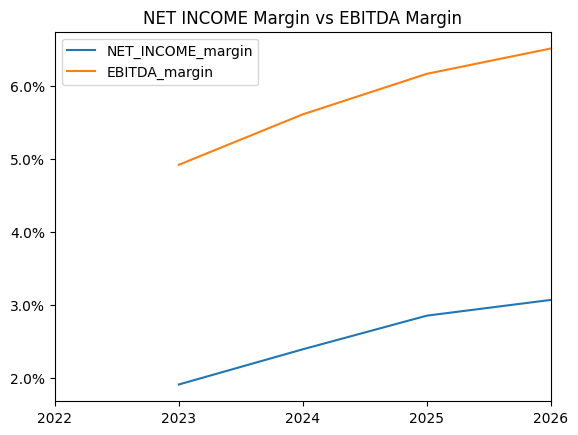

In [111]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Assuming df_fin_ratios is your DataFrame containing the financial ratios
# Make sure you have already created this DataFrame

# Plotting the specified columns
ax = df_fin_ratios[['NET_INCOME_margin','EBITDA_margin']].plot.line()

# Setting the y-axis formatter to display values as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter())

# Adding title
plt.title('NET INCOME Margin vs EBITDA Margin')

# Displaying the plot
plt.show()

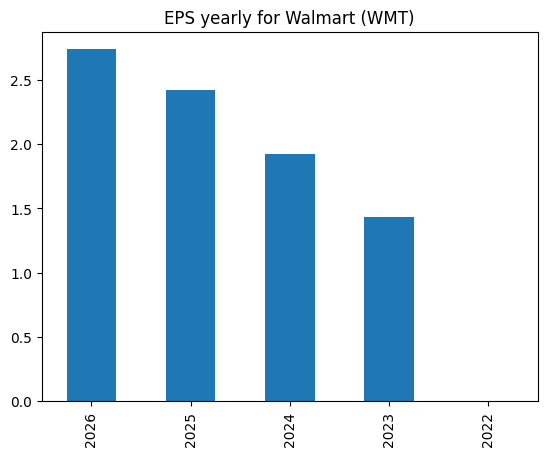

In [112]:
EPS_year = df_fin_ratios['EPS'].index.year

df_fin_ratios['EPS'].plot.bar(title = 'EPS yearly for Walmart (WMT)')

plt.xticks(range(len(EPS_year)), EPS_year)
# Displaying the plot
plt.show()

# 5) [Code snippet 7] Daily OHCLV data for a set of stocks

In [113]:
# https://companiesmarketcap.com/usa/largest-companies-in-the-usa-by-market-cap/
US_STOCKS = ['MSFT', 'AAPL', 'GOOG', 'NVDA', 'AMZN', 'META', 'BRK-B', 'LLY', 'AVGO','V', 'JPM']

# You're required to add EU_STOCKS and INDIA_STOCS
# https://companiesmarketcap.com/european-union/largest-companies-in-the-eu-by-market-cap/
EU_STOCKS = ['NVO','MC.PA', 'ASML', 'RMS.PA', 'OR.PA', 'SAP', 'ACN', 'TTE', 'SIE.DE','IDEXY','CDI.PA']

# https://companiesmarketcap.com/india/largest-companies-in-india-by-market-cap/
INDIA_STOCKS = ['RELIANCE.NS','TCS.NS','HDB','BHARTIARTL.NS','IBN','SBIN.NS','LICI.NS','INFY','ITC.NS','HINDUNILVR.NS','LT.NS']

In [114]:
ALL_TICKERS = US_STOCKS  + EU_STOCKS + INDIA_STOCKS
ALL_TICKERS

['MSFT',
 'AAPL',
 'GOOG',
 'NVDA',
 'AMZN',
 'META',
 'BRK-B',
 'LLY',
 'AVGO',
 'V',
 'JPM',
 'NVO',
 'MC.PA',
 'ASML',
 'RMS.PA',
 'OR.PA',
 'SAP',
 'ACN',
 'TTE',
 'SIE.DE',
 'IDEXY',
 'CDI.PA',
 'RELIANCE.NS',
 'TCS.NS',
 'HDB',
 'BHARTIARTL.NS',
 'IBN',
 'SBIN.NS',
 'LICI.NS',
 'INFY',
 'ITC.NS',
 'HINDUNILVR.NS',
 'LT.NS']

In [115]:
import time

stocks_df = pd.DataFrame({'A' : []})

for i,ticker in enumerate(ALL_TICKERS):
  print(i,ticker)

  # Work with stock prices
  ticker_obj = yf.Ticker(ticker)

  # historyPrices = yf.download(tickers = ticker,
  #                    period = "max",
  #                    interval = "1d")
  historyPrices = ticker_obj.history(
                     period = "max",
                     interval = "1d")

  # generate features for historical prices, and what we want to predict
  historyPrices['Ticker'] = ticker
  historyPrices['Year']= historyPrices.index.year
  historyPrices['Month'] = historyPrices.index.month
  historyPrices['Weekday'] = historyPrices.index.weekday
  historyPrices['Date'] = historyPrices.index.date

  # historical returns
  for i in [1,3,7,30,90,365]:
    historyPrices['growth_'+str(i)+'d'] = historyPrices['Close'] / historyPrices['Close'].shift(i)
  historyPrices['growth_future_30d'] = historyPrices['Close'].shift(-30) / historyPrices['Close']

  # Technical indicators
  # SimpleMovingAverage 10 days and 20 days
  historyPrices['SMA10']= historyPrices['Close'].rolling(10).mean()
  historyPrices['SMA20']= historyPrices['Close'].rolling(20).mean()
  historyPrices['growing_moving_average'] = np.where(historyPrices['SMA10'] > historyPrices['SMA20'], 1, 0)
  historyPrices['high_minus_low_relative'] = (historyPrices.High - historyPrices.Low) / historyPrices['Close']

  # 30d rolling volatility : https://ycharts.com/glossary/terms/rolling_vol_30
  #ERROR, fixed in 2025: historyPrices['volatility'] =   historyPrices['Close'].rolling(30).std() * np.sqrt(252)
  # volatility is calculated on std. dev. or Returns and NOT Close price
  historyPrices['volatility'] = historyPrices['growth_1d'].rolling(30).std() * np.sqrt(252)

  # what we want to predict
  historyPrices['is_positive_growth_30d_future'] = np.where(historyPrices['growth_future_30d'] > 1, 1, 0)

  # sleep 1 sec between downloads - not to overload the API server
  time.sleep(1)


  if stocks_df.empty:
    stocks_df = historyPrices
  else:
    stocks_df = pd.concat([stocks_df, historyPrices], ignore_index=True)

0 MSFT
1 AAPL
2 GOOG
3 NVDA
4 AMZN
5 META
6 BRK-B
7 LLY
8 AVGO
9 V
10 JPM
11 NVO
12 MC.PA
13 ASML
14 RMS.PA
15 OR.PA
16 SAP
17 ACN
18 TTE
19 SIE.DE
20 IDEXY
21 CDI.PA
22 RELIANCE.NS
23 TCS.NS
24 HDB
25 BHARTIARTL.NS
26 IBN
27 SBIN.NS
28 LICI.NS
29 INFY
30 ITC.NS
31 HINDUNILVR.NS
32 LT.NS


In [116]:
def get_ticker_type(ticker:str, us_stocks_list, eu_stocks_list, india_stocks_list):
  if ticker in us_stocks_list:
    return 'US'
  elif ticker in eu_stocks_list:
    return 'EU'
  elif ticker in india_stocks_list:
    return 'INDIA'
  else:
    return 'ERROR'


In [117]:
stocks_df['ticker_type'] = stocks_df.Ticker.apply(lambda x:get_ticker_type(x, US_STOCKS, EU_STOCKS, INDIA_STOCKS))

In [118]:
# count of observations between US-EU-INDIA stocks
stocks_df.ticker_type.value_counts()

,count
ticker_type,
US,87218
EU,83615
INDIA,69818


In [119]:
# unique tickers
stocks_df.Ticker.nunique()

33

In [120]:
# count of observations by stock
stocks_df.Ticker.value_counts()

,count
Ticker,
LLY,13685
JPM,11719
AAPL,11531
NVO,11436
MSFT,10205
CDI.PA,8930
TTE,8783
ASML,7928
SAP,7799


In [121]:
stocks_df.groupby(['Ticker','ticker_type']).Date.agg(['min','max'])

,,min,max
Ticker,ticker_type,,
AAPL,US,1980-12-12,2026-09-15
ACN,EU,2001-07-19,2026-09-15
AMZN,US,1997-05-15,2026-09-15
ASML,EU,1995-03-15,2026-09-15
AVGO,US,2009-08-06,2026-09-15
BHARTIARTL.NS,INDIA,2002-07-01,2026-09-15
BRK-B,US,1996-05-09,2026-09-15
CDI.PA,EU,1992-01-27,2026-09-15
GOOG,US,2004-08-19,2026-09-15


In [122]:
#  average growth 365days
stocks_df[stocks_df.Year>=2020].groupby(by=['Year','ticker_type']).growth_365d.mean()

Year  ticker_type
2020  EU             1.247263
      INDIA          1.102299
      US             1.484070
2021  EU             1.583642
      INDIA          1.547188
      US             1.797571
2022  EU             1.191194
      INDIA          1.381114
      US             1.182379
2023  EU             1.246429
      INDIA          1.205688
      US             1.203253
2024  EU             1.406815
      INDIA          1.358507
      US             2.159361
2025  EU             1.061778
      INDIA          1.166797
      US             1.583906
2026  EU             1.049122
      INDIA          0.943581
      US             1.364607
Name: growth_365d, dtype: float64

In [123]:
stocks_df['Date'] = pd.to_datetime(stocks_df['Date'])

In [124]:
# filtering only on stats after 2000
stocks_df[stocks_df.Date>='2000-01-01'].info()

<class 'pandas.core.frame.DataFrame'>
Index: 202184 entries, 3490 to 240650
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Open                           202184 non-null  float64       
 1   High                           202184 non-null  float64       
 2   Low                            202184 non-null  float64       
 3   Close                          202184 non-null  float64       
 4   Volume                         202184 non-null  int64         
 5   Dividends                      202184 non-null  float64       
 6   Stock Splits                   202184 non-null  float64       
 7   Ticker                         202184 non-null  object        
 8   Year                           202184 non-null  int32         
 9   Month                          202184 non-null  int32         
 10  Weekday                        202184 non-null  int32         
 11  Da

In [125]:
stocks_df[stocks_df.Date=='2025-04-01'].tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_90d,growth_365d,growth_future_30d,SMA10,SMA20,growing_moving_average,high_minus_low_relative,volatility,is_positive_growth_30d_future,ticker_type
211935,383.312930,388.616631,381.914670,384.638855,1453754,0.0,0.0,LICI.NS,2025,4,...,0.904530,1.249596,1.071827,379.364111,370.261031,1,0.017424,0.257048,1,INDIA
218854,17.297072,17.316089,17.068854,17.306581,13574900,0.0,0.0,INFY,2025,4,...,0.842593,1.105543,1.014286,17.527191,17.811038,0,0.014286,0.211017,1,INDIA
226563,383.673534,387.980270,379.741319,380.724365,15206240,0.0,0.0,ITC.NS,2025,4,...,0.938373,1.003170,1.070577,381.571646,380.401346,1,0.021640,0.140684,1,INDIA
234273,2195.721287,2220.652688,2157.813748,2171.275879,2495962,0.0,0.0,HINDUNILVR.NS,2025,4,...,0.937490,0.919659,1.066634,2174.405469,2153.075183,1,0.028941,0.177949,1,INDIA
240287,3414.493704,3435.687209,3365.434886,3372.106934,1935147,0.0,0.0,LT.NS,2025,4,...,0.986594,1.119635,1.047544,3344.531006,3246.175403,1,0.020833,0.215693,1,INDIA


#6) [Code Snippet 8] Technical Indicators with TA-lib
* PythonInvest article on Tech. Indicators
* Code for generating 100+ tech. indicators/patterns : https://github.com/realmistic/PythonInvest-basic-fin-analysis/blob/master/colab_notebooks/Part14_Exploring_Tech_Indicators_For_Stocks_and_Crypto.ipynb

Indicator groups: https://github.com/TA-Lib/ta-lib-python/blob/master/README.md

* Overlap Studies (17)
* Momentum Indicators (30+)
* Volume Indicators (3)
* Cycle Indicators (5)
* Price Transform (4)
* Volatility Indicators (3)
* Pattern Recognition (60)

In [126]:
# https://stackoverflow.com/questions/49648391/how-to-install-ta-lib-in-google-colab
# Update (apr 2023): Colab is now Python 3.10
# there are some other (older) ways to install talib

# url = 'https://anaconda.org/conda-forge/libta-lib/0.4.0/download/linux-64/libta-lib-0.4.0-h166bdaf_1.tar.bz2'
# !curl -L $url | tar xj -C /usr/lib/x86_64-linux-gnu/ lib --strip-components=1
# url = 'https://anaconda.org/conda-forge/ta-lib/0.4.19/download/linux-64/ta-lib-0.4.19-py310hde88566_4.tar.bz2'
# !curl -L $url | tar xj -C /usr/local/lib/python3.10/dist-packages/ lib/python3.10/site-packages/talib --strip-components=3
# import talib

In [127]:
url = 'https://anaconda.org/conda-forge/libta-lib/0.4.0/download/linux-64/libta-lib-0.4.0-h166bdaf_1.tar.bz2'
!curl -L $url | tar xj -C /usr/lib/x86_64-linux-gnu/ lib --strip-components=1
# Install ta-lib directly using pip, which is more likely to find a compatible wheel for the current Python version
!pip install ta-lib
import talib

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  4055    0  4055    0     0  27500      0 --:--:-- --:--:-- --:--:-- 27398
100  517k  100  517k    0     0  1363k      0 --:--:-- --:--:-- --:--:-- 1363k
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 87.3 MB/s eta 0:00:00


## 6.1) Momentum indicators
https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/momentum_indicators.md

In [128]:
def talib_get_momentum_indicators_for_one_ticker(df: pd.DataFrame) -> pd.DataFrame:
  # ADX - Average Directional Movement Index
  talib_momentum_adx = talib.ADX(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # ADXR - Average Directional Movement Index Rating
  talib_momentum_adxr = talib.ADXR(df.High.values, df.Low.values, df.Close.values, timeperiod=14 )
  # APO - Absolute Price Oscillator
  talib_momentum_apo = talib.APO(df.Close.values, fastperiod=12, slowperiod=26, matype=0 )
  # AROON - Aroon
  talib_momentum_aroon = talib.AROON(df.High.values, df.Low.values, timeperiod=14 )
  # talib_momentum_aroon[0].size
  # talib_momentum_aroon[1].size
  # AROONOSC - Aroon Oscillator
  talib_momentum_aroonosc = talib.AROONOSC(df.High.values, df.Low.values, timeperiod=14)
  # BOP - Balance of Power
  # https://school.stockcharts.com/doku.php?id=technical_indicators:balance_of_power
     #calculate open prices as shifted closed prices from the prev day
     # open = df.Last.shift(1)
  talib_momentum_bop = talib.BOP(df.Open.values, df.High.values, df.Low.values, df.Close.values)
  # CCI - Commodity Channel Index
  talib_momentum_cci = talib.CCI(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # CMO - Chande Momentum Oscillator
  talib_momentum_cmo = talib.CMO(df.Close.values, timeperiod=14)
  # DX - Directional Movement Index
  talib_momentum_dx = talib.DX(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # MACD - Moving Average Convergence/Divergence
  talib_momentum_macd, talib_momentum_macdsignal, talib_momentum_macdhist = talib.MACD(df.Close.values, fastperiod=12, \
                                                                                       slowperiod=26, signalperiod=9)
  # MACDEXT - MACD with controllable MA type
  talib_momentum_macd_ext, talib_momentum_macdsignal_ext, talib_momentum_macdhist_ext = talib.MACDEXT(df.Close.values, \
                                                                                                    fastperiod=12, \
                                                                                                    fastmatype=0, \
                                                                                                    slowperiod=26, \
                                                                                                    slowmatype=0, \
                                                                                                    signalperiod=9, \
                                                                                                  signalmatype=0)
  # MACDFIX - Moving Average Convergence/Divergence Fix 12/26
  talib_momentum_macd_fix, talib_momentum_macdsignal_fix, talib_momentum_macdhist_fix = talib.MACDFIX(df.Close.values, \
                                                                                                      signalperiod=9)
  # MFI - Money Flow Index
  talib_momentum_mfi = talib.MFI(df.High.values, df.Low.values, df.Close.values, df.Volume.values, timeperiod=14)
  # MINUS_DI - Minus Directional Indicator
  talib_momentum_minus_di = talib.MINUS_DM(df.High.values, df.Low.values, timeperiod=14)
  # MOM - Momentum
  talib_momentum_mom = talib.MOM(df.Close.values, timeperiod=10)
  # PLUS_DI - Plus Directional Indicator
  talib_momentum_plus_di = talib.PLUS_DI(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # PLUS_DM - Plus Directional Movement
  talib_momentum_plus_dm = talib.PLUS_DM(df.High.values, df.Low.values, timeperiod=14)
  # PPO - Percentage Price Oscillator
  talib_momentum_ppo = talib.PPO(df.Close.values, fastperiod=12, slowperiod=26, matype=0)
  # ROC - Rate of change : ((price/prevPrice)-1)*100
  talib_momentum_roc = talib.ROC(df.Close.values, timeperiod=10)
  # ROCP - Rate of change Percentage: (price-prevPrice)/prevPrice
  talib_momentum_rocp = talib.ROCP(df.Close.values, timeperiod=10)
  # ROCR - Rate of change ratio: (price/prevPrice)
  talib_momentum_rocr = talib.ROCR(df.Close.values, timeperiod=10)
  # ROCR100 - Rate of change ratio 100 scale: (price/prevPrice)*100
  talib_momentum_rocr100 = talib.ROCR100(df.Close.values, timeperiod=10)
  # RSI - Relative Strength Index
  talib_momentum_rsi = talib.RSI(df.Close.values, timeperiod=14)
  # STOCH - Stochastic
  talib_momentum_slowk, talib_momentum_slowd = talib.STOCH(df.High.values, df.Low.values, df.Close.values, \
                                                           fastk_period=5, slowk_period=3, slowk_matype=0, slowd_period=3, slowd_matype=0)
  # STOCHF - Stochastic Fast
  talib_momentum_fastk, talib_momentum_fastd = talib.STOCHF(df.High.values, df.Low.values, df.Close.values, \
                                                            fastk_period=5, fastd_period=3, fastd_matype=0)
  # STOCHRSI - Stochastic Relative Strength Index
  talib_momentum_fastk_rsi, talib_momentum_fastd_rsi = talib.STOCHRSI(df.Close.values, timeperiod=14, \
                                                                      fastk_period=5, fastd_period=3, fastd_matype=0)
  # TRIX - 1-day Rate-Of-Change (ROC) of a Triple Smooth EMA
  talib_momentum_trix = talib.TRIX(df.Close.values, timeperiod=30)
  # ULTOSC - Ultimate Oscillator
  talib_momentum_ultosc = talib.ULTOSC(df.High.values, df.Low.values, df.Close.values, timeperiod1=7, timeperiod2=14, timeperiod3=28)
  # WILLR - Williams' %R
  talib_momentum_willr = talib.WILLR(df.High.values, df.Low.values, df.Close.values, timeperiod=14)

  momentum_df =   pd.DataFrame(
    {
      # assume here multi-index <dateTime, ticker>
      # 'datetime': df.index.get_level_values(0),
      # 'ticker': df.index.get_level_values(1) ,

      # old way with separate columns
      'Date': df.Date.values,
      'Ticker': df.Ticker,

      'adx': talib_momentum_adx,
      'adxr': talib_momentum_adxr,
      'apo': talib_momentum_apo,
      'aroon_1': talib_momentum_aroon[0] ,
      'aroon_2': talib_momentum_aroon[1],
      'aroonosc': talib_momentum_aroonosc,
      'bop': talib_momentum_bop,
      'cci': talib_momentum_cci,
      'cmo': talib_momentum_cmo,
      'dx': talib_momentum_dx,
      'macd': talib_momentum_macd,
      'macdsignal': talib_momentum_macdsignal,
      'macdhist': talib_momentum_macdhist,
      'macd_ext': talib_momentum_macd_ext,
      'macdsignal_ext': talib_momentum_macdsignal_ext,
      'macdhist_ext': talib_momentum_macdhist_ext,
      'macd_fix': talib_momentum_macd_fix,
      'macdsignal_fix': talib_momentum_macdsignal_fix,
      'macdhist_fix': talib_momentum_macdhist_fix,
      'mfi': talib_momentum_mfi,
      'minus_di': talib_momentum_minus_di,
      'mom': talib_momentum_mom,
      'plus_di': talib_momentum_plus_di,
      'dm': talib_momentum_plus_dm,
      'ppo': talib_momentum_ppo,
      'roc': talib_momentum_roc,
      'rocp': talib_momentum_rocp,
      'rocr': talib_momentum_rocr,
      'rocr100': talib_momentum_rocr100,
      'rsi': talib_momentum_rsi,
      'slowk': talib_momentum_slowk,
      'slowd': talib_momentum_slowd,
      'fastk': talib_momentum_fastk,
      'fastd': talib_momentum_fastd,
      'fastk_rsi': talib_momentum_fastk_rsi,
      'fastd_rsi': talib_momentum_fastd_rsi,
      'trix': talib_momentum_trix,
      'ultosc': talib_momentum_ultosc,
      'willr': talib_momentum_willr,
     }
  )
  return momentum_df

## 6.2 Volume, Volatility, Cycle, Price indicators
https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/volume_indicators.md

In [129]:
def talib_get_volume_volatility_cycle_price_indicators(df: pd.DataFrame) -> pd.DataFrame:
        # TA-Lib Volume indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/volume_indicators.md
        # AD - Chaikin A/D Line
        talib_ad = talib.AD(
            df.High.values, df.Low.values, df.Close.values, df.Volume.values)
        # ADOSC - Chaikin A/D Oscillator
        talib_adosc = talib.ADOSC(
            df.High.values, df.Low.values, df.Close.values, df.Volume.values, fastperiod=3, slowperiod=10)
        # OBV - On Balance Volume
        talib_obv = talib.OBV(
            df.Close.values, df.Volume.values)

        # TA-Lib Volatility indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/volatility_indicators.md
        # ATR - Average True Range
        talib_atr = talib.ATR(
            df.High.values, df.Low.values, df.Close.values, timeperiod=14)
        # NATR - Normalized Average True Range
        talib_natr = talib.NATR(
            df.High.values, df.Low.values, df.Close.values, timeperiod=14)
        # OBV - On Balance Volume
        talib_obv = talib.OBV(
            df.Close.values, df.Volume.values)

        # TA-Lib Cycle Indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/cycle_indicators.md
        # HT_DCPERIOD - Hilbert Transform - Dominant Cycle Period
        talib_ht_dcperiod = talib.HT_DCPERIOD(df.Close.values)
        # HT_DCPHASE - Hilbert Transform - Dominant Cycle Phase
        talib_ht_dcphase = talib.HT_DCPHASE(df.Close.values)
        # HT_PHASOR - Hilbert Transform - Phasor Components
        talib_ht_phasor_inphase, talib_ht_phasor_quadrature = talib.HT_PHASOR(
            df.Close.values)
        # HT_SINE - Hilbert Transform - SineWave
        talib_ht_sine_sine, talib_ht_sine_leadsine = talib.HT_SINE(
            df.Close.values)
        # HT_TRENDMODE - Hilbert Transform - Trend vs Cycle Mode
        talib_ht_trendmode = talib.HT_TRENDMODE(df.Close.values)

        # TA-Lib Price Transform Functions
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/price_transform.md
        # AVGPRICE - Average Price
        talib_avgprice = talib.AVGPRICE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # MEDPRICE - Median Price
        talib_medprice = talib.MEDPRICE(df.High.values, df.Low.values)
        # TYPPRICE - Typical Price
        talib_typprice = talib.TYPPRICE(
            df.High.values, df.Low.values, df.Close.values)
        # WCLPRICE - Weighted Close Price
        talib_wclprice = talib.WCLPRICE(
            df.High.values, df.Low.values, df.Close.values)

        volume_volatility_cycle_price_df = pd.DataFrame(
            {'Date': df.Date.values,
             'Ticker': df.Ticker,
             # TA-Lib Volume indicators
             'ad': talib_ad,
             'adosc': talib_adosc,
             'obv': talib_obv,
             # TA-Lib Volatility indicators
             'atr': talib_atr,
             'natr': talib_natr,
             'obv': talib_obv,
             # TA-Lib Cycle Indicators
             'ht_dcperiod': talib_ht_dcperiod,
             'ht_dcphase': talib_ht_dcphase,
             'ht_phasor_inphase': talib_ht_phasor_inphase,
             'ht_phasor_quadrature': talib_ht_phasor_quadrature,
             'ht_sine_sine': talib_ht_sine_sine,
             'ht_sine_leadsine': talib_ht_sine_leadsine,
             'ht_trendmod': talib_ht_trendmode,
             # TA-Lib Price Transform Functions
             'avgprice': talib_avgprice,
             'medprice': talib_medprice,
             'typprice': talib_typprice,
             'wclprice': talib_wclprice,
             }
        )

        # Need a proper date type
        volume_volatility_cycle_price_df['Date'] = pd.to_datetime(
            volume_volatility_cycle_price_df['Date'])

        return volume_volatility_cycle_price_df

## 6.3) Pattern indicators
https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/pattern_recognition.md

In [130]:
def talib_get_pattern_recognition_indicators(df: pd.DataFrame) -> pd.DataFrame:
# TA-Lib Pattern Recognition indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/pattern_recognition.md
        # Nice article about candles (pattern recognition) https://medium.com/analytics-vidhya/recognizing-over-50-candlestick-patterns-with-python-4f02a1822cb5

        # CDL2CROWS - Two Crows
        talib_cdl2crows = talib.CDL2CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3BLACKCROWS - Three Black Crows
        talib_cdl3blackrows = talib.CDL3BLACKCROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3INSIDE - Three Inside Up/Down
        talib_cdl3inside = talib.CDL3INSIDE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3LINESTRIKE - Three-Line Strike
        talib_cdl3linestrike = talib.CDL3LINESTRIKE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3OUTSIDE - Three Outside Up/Down
        talib_cdl3outside = talib.CDL3OUTSIDE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3STARSINSOUTH - Three Stars In The South
        talib_cdl3starsinsouth = talib.CDL3STARSINSOUTH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3WHITESOLDIERS - Three Advancing White Soldiers
        talib_cdl3whitesoldiers = talib.CDL3WHITESOLDIERS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLABANDONEDBABY - Abandoned Baby
        talib_cdlabandonedbaby = talib.CDLABANDONEDBABY(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLADVANCEBLOCK - Advance Block
        talib_cdladvancedblock = talib.CDLADVANCEBLOCK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLBELTHOLD - Belt-hold
        talib_cdlbelthold = talib.CDLBELTHOLD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLBREAKAWAY - Breakaway
        talib_cdlbreakaway = talib.CDLBREAKAWAY(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCLOSINGMARUBOZU - Closing Marubozu
        talib_cdlclosingmarubozu = talib.CDLCLOSINGMARUBOZU(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCONCEALBABYSWALL - Concealing Baby Swallow
        talib_cdlconcealbabyswall = talib.CDLCONCEALBABYSWALL(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCOUNTERATTACK - Counterattack
        talib_cdlcounterattack = talib.CDLCOUNTERATTACK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDARKCLOUDCOVER - Dark Cloud Cover
        talib_cdldarkcloudcover = talib.CDLDARKCLOUDCOVER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLDOJI - Doji
        talib_cdldoji = talib.CDLDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDOJISTAR - Doji Star
        talib_cdldojistar = talib.CDLDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDRAGONFLYDOJI - Dragonfly Doji
        talib_cdldragonflydoji = talib.CDLDRAGONFLYDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLENGULFING - Engulfing Pattern
        talib_cdlengulfing = talib.CDLENGULFING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLEVENINGDOJISTAR - Evening Doji Star
        talib_cdleveningdojistar = talib.CDLEVENINGDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLEVENINGSTAR - Evening Star
        talib_cdleveningstar = talib.CDLEVENINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLGAPSIDESIDEWHITE - Up/Down-gap side-by-side white lines
        talib_cdlgapsidesidewhite = talib.CDLGAPSIDESIDEWHITE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLGRAVESTONEDOJI - Gravestone Doji
        talib_cdlgravestonedoji = talib.CDLGRAVESTONEDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHAMMER - Hammer
        talib_cdlhammer = talib.CDLHAMMER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHANGINGMAN - Hanging Man
        talib_cdlhangingman = talib.CDLHANGINGMAN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHARAMI - Harami Pattern
        talib_cdlharami = talib.CDLHARAMI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHARAMICROSS - Harami Cross Pattern
        talib_cdlharamicross = talib.CDLHARAMICROSS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIGHWAVE - High-Wave Candle
        talib_cdlhighwave = talib.CDLHIGHWAVE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIKKAKE - Hikkake Pattern
        talib_cdlhikkake = talib.CDLHIKKAKE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIKKAKEMOD - Modified Hikkake Pattern
        talib_cdlhikkakemod = talib.CDLHIKKAKEMOD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLHOMINGPIGEON - Homing Pigeon
        talib_cdlhomingpigeon = talib.CDLHOMINGPIGEON(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLIDENTICAL3CROWS - Identical Three Crows
        talib_cdlidentical3crows = talib.CDLIDENTICAL3CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLINNECK - In-Neck Pattern
        talib_cdlinneck = talib.CDLINNECK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLINVERTEDHAMMER - Inverted Hammer
        talib_cdlinvertedhammer = talib.CDLINVERTEDHAMMER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLKICKING - Kicking
        talib_cdlkicking = talib.CDLKICKING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLKICKINGBYLENGTH - Kicking - bull/bear determined by the longer marubozu
        talib_cdlkickingbylength = talib.CDLKICKINGBYLENGTH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLADDERBOTTOM - Ladder Bottom
        talib_cdlladderbottom = talib.CDLLADDERBOTTOM(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLONGLEGGEDDOJI - Long Legged Doji
        talib_cdllongleggeddoji = talib.CDLLONGLEGGEDDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLONGLINE - Long Line Candle
        talib_cdllongline = talib.CDLLONGLINE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLMARUBOZU - Marubozu
        talib_cdlmarubozu = talib.CDLMARUBOZU(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLMATCHINGLOW - Matching Low
        talib_cdlmatchinglow = talib.CDLMATCHINGLOW(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLMATHOLD - Mat Hold
        talib_cdlmathold = talib.CDLMATHOLD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLMORNINGDOJISTAR - Morning Doji Star
        talib_cdlmorningdojistar = talib.CDLMORNINGDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLMORNINGSTAR - Morning Star
        talib_cdlmorningstar = talib.CDLMORNINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLONNECK - On-Neck Pattern
        talib_cdlonneck = talib.CDLONNECK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLPIERCING - Piercing Pattern
        talib_cdlpiercing = talib.CDLPIERCING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLRICKSHAWMAN - Rickshaw Man
        talib_cdlrickshawman = talib.CDLRICKSHAWMAN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLRISEFALL3METHODS - Rising/Falling Three Methods
        talib_cdlrisefall3methods = talib.CDLRISEFALL3METHODS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSEPARATINGLINES - Separating Lines
        talib_cdlseparatinglines = talib.CDLSEPARATINGLINES(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSHOOTINGSTAR - Shooting Star
        talib_cdlshootingstar = talib.CDLSHOOTINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSHORTLINE - Short Line Candle
        talib_cdlshortline = talib.CDLSHORTLINE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSPINNINGTOP - Spinning Top
        talib_cdlspinningtop = talib.CDLSPINNINGTOP(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLSTALLEDPATTERN - Stalled Pattern
        talib_cdlstalledpattern = talib.CDLSTALLEDPATTERN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSTICKSANDWICH - Stick Sandwich
        talib_cdlsticksandwich = talib.CDLSTICKSANDWICH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTAKURI - Takuri (Dragonfly Doji with very long lower shadow)
        talib_cdltakuru = talib.CDLTAKURI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTASUKIGAP - Tasuki Gap
        talib_cdltasukigap = talib.CDLTASUKIGAP(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTHRUSTING - Thrusting Pattern
        talib_cdlthrusting = talib.CDLTHRUSTING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTRISTAR - Tristar Pattern
        talib_cdltristar = talib.CDLTRISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLUNIQUE3RIVER - Unique 3 River
        talib_cdlunique3river = talib.CDLUNIQUE3RIVER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLUPSIDEGAP2CROWS - Upside Gap Two Crows
        talib_cdlupsidegap2crows = talib.CDLUPSIDEGAP2CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLXSIDEGAP3METHODS - Upside/Downside Gap Three Methods
        talib_cdlxsidegap3methods = talib.CDLXSIDEGAP3METHODS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        pattern_indicators_df = pd.DataFrame(
            {'Date': df.Date.values,
             'Ticker': df.Ticker,
             # TA-Lib Pattern Recognition indicators
             'cdl2crows': talib_cdl2crows,
             'cdl3blackrows': talib_cdl3blackrows,
             'cdl3inside': talib_cdl3inside,
             'cdl3linestrike': talib_cdl3linestrike,
             'cdl3outside': talib_cdl3outside,
             'cdl3starsinsouth': talib_cdl3starsinsouth,
             'cdl3whitesoldiers': talib_cdl3whitesoldiers,
             'cdlabandonedbaby': talib_cdlabandonedbaby,
             'cdladvancedblock': talib_cdladvancedblock,
             'cdlbelthold': talib_cdlbelthold,
             'cdlbreakaway': talib_cdlbreakaway,
             'cdlclosingmarubozu': talib_cdlclosingmarubozu,
             'cdlconcealbabyswall': talib_cdlconcealbabyswall,
             'cdlcounterattack': talib_cdlcounterattack,
             'cdldarkcloudcover': talib_cdldarkcloudcover,
             'cdldoji': talib_cdldoji,
             'cdldojistar': talib_cdldojistar,
             'cdldragonflydoji': talib_cdldragonflydoji,
             'cdlengulfing': talib_cdlengulfing,
             'cdleveningdojistar': talib_cdleveningdojistar,
             'cdleveningstar': talib_cdleveningstar,
             'cdlgapsidesidewhite': talib_cdlgapsidesidewhite,
             'cdlgravestonedoji': talib_cdlgravestonedoji,
             'cdlhammer': talib_cdlhammer,
             'cdlhangingman': talib_cdlhangingman,
             'cdlharami': talib_cdlharami,
             'cdlharamicross': talib_cdlharamicross,
             'cdlhighwave': talib_cdlhighwave,
             'cdlhikkake': talib_cdlhikkake,
             'cdlhikkakemod': talib_cdlhikkakemod,
             'cdlhomingpigeon': talib_cdlhomingpigeon,
             'cdlidentical3crows': talib_cdlidentical3crows,
             'cdlinneck': talib_cdlinneck,
             'cdlinvertedhammer': talib_cdlinvertedhammer,
             'cdlkicking': talib_cdlkicking,
             'cdlkickingbylength': talib_cdlkickingbylength,
             'cdlladderbottom': talib_cdlladderbottom,
             'cdllongleggeddoji': talib_cdllongleggeddoji,
             'cdllongline': talib_cdllongline,
             'cdlmarubozu': talib_cdlmarubozu,
             'cdlmatchinglow': talib_cdlmatchinglow,
             'cdlmathold': talib_cdlmathold,
             'cdlmorningdojistar': talib_cdlmorningdojistar,
             'cdlmorningstar': talib_cdlmorningstar,
             'cdlonneck': talib_cdlonneck,
             'cdlpiercing': talib_cdlpiercing,
             'cdlrickshawman': talib_cdlrickshawman,
             'cdlrisefall3methods': talib_cdlrisefall3methods,
             'cdlseparatinglines': talib_cdlseparatinglines,
             'cdlshootingstar': talib_cdlshootingstar,
             'cdlshortline': talib_cdlshortline,
             'cdlspinningtop': talib_cdlspinningtop,
             'cdlstalledpattern': talib_cdlstalledpattern,
             'cdlsticksandwich': talib_cdlsticksandwich,
             'cdltakuru': talib_cdltakuru,
             'cdltasukigap': talib_cdltasukigap,
             'cdlthrusting': talib_cdlthrusting,
             'cdltristar': talib_cdltristar,
             'cdlunique3river': talib_cdlunique3river,
             'cdlupsidegap2crows': talib_cdlupsidegap2crows,
             'cdlxsidegap3methods': talib_cdlxsidegap3methods
             }
        )

        # Need a proper date type
        pattern_indicators_df['Date'] = pd.to_datetime(
            pattern_indicators_df['Date'])

        return pattern_indicators_df

## 6.4) Calculate Tech Indicators and Merge to the original dataframe

In [131]:
print('talib_get_momentum_indicators_for_one_ticker' in globals())
print('talib_get_volume_volatility_cycle_price_indicators' in globals())
print('talib_get_pattern_recognition_indicators' in globals())

True
True
True


In [132]:
# Volume needs to be float, not int
stocks_df['Volume'] = stocks_df['Volume']*1.0

In [133]:
# to resolve an error "Exception: input array type is not double"
# https://stackoverflow.com/questions/51712269/how-to-run-ta-lib-on-multiple-columns-of-a-pandas-dataframe
for f in ['Open','High','Low','Close', 'Volume', 'Close']:
  stocks_df.loc[:,f] = stocks_df.loc[:,f].astype('float64')

In [134]:
stocks_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240651 entries, 0 to 240650
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Open                           240651 non-null  float64       
 1   High                           240651 non-null  float64       
 2   Low                            240651 non-null  float64       
 3   Close                          240651 non-null  float64       
 4   Volume                         240651 non-null  float64       
 5   Dividends                      240651 non-null  float64       
 6   Stock Splits                   240651 non-null  float64       
 7   Ticker                         240651 non-null  object        
 8   Year                           240651 non-null  int32         
 9   Month                          240651 non-null  int32         
 10  Weekday                        240651 non-null  int32         
 11  

In [135]:
import pandas as pd
# supress warnings
pd.options.mode.chained_assignment = None  # default='warn'

# adding Momentum / Pattern/ Volume features to all tickers - one by one
merged_df_with_tech_ind = pd.DataFrame({'A' : []})

current_ticker_data = None
i=0
for ticker in ALL_TICKERS:
  i+=1
  print(f'{i}/{len(ALL_TICKERS)} Current ticker is {ticker}')
  current_ticker_data = stocks_df[stocks_df.Ticker.isin([ticker])]
  # need to have same 'utc' time on both sides
  # https://stackoverflow.com/questions/73964894/you-are-trying-to-merge-on-datetime64ns-utc-and-datetime64ns-columns-if-yo
  current_ticker_data['Date']= pd.to_datetime(current_ticker_data['Date'], utc=True)

  # 3 calls to get additional features
  df_current_ticker_momentum_indicators = talib_get_momentum_indicators_for_one_ticker(current_ticker_data)
  df_current_ticker_momentum_indicators["Date"]= pd.to_datetime(df_current_ticker_momentum_indicators['Date'], utc=True)
  # df_current_ticker_momentum_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_momentum_indicators['Date'], utc=True)

  df_current_ticker_volume_indicators = talib_get_volume_volatility_cycle_price_indicators(current_ticker_data)
  df_current_ticker_volume_indicators["Date"]= pd.to_datetime(df_current_ticker_volume_indicators['Date'], utc=True)
  # df_current_ticker_volume_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_volume_indicators['Date'], utc=True)

  df_current_ticker_pattern_indicators = talib_get_pattern_recognition_indicators(current_ticker_data)
  df_current_ticker_pattern_indicators["Date"]= pd.to_datetime(df_current_ticker_pattern_indicators['Date'], utc=True)
  # df_current_ticker_pattern_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_pattern_indicators['Date'], utc=True)

  # merge to one df
  m1 = pd.merge(current_ticker_data, df_current_ticker_momentum_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")
  m2 = pd.merge(m1, df_current_ticker_volume_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")
  m3 = pd.merge(m2, df_current_ticker_pattern_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")

  if merged_df_with_tech_ind.empty:
    merged_df_with_tech_ind = m3
  else:
    merged_df_with_tech_ind = pd.concat([merged_df_with_tech_ind,m3], ignore_index = False)

1/33 Current ticker is MSFT
2/33 Current ticker is AAPL
3/33 Current ticker is GOOG
4/33 Current ticker is NVDA
5/33 Current ticker is AMZN
6/33 Current ticker is META
7/33 Current ticker is BRK-B
8/33 Current ticker is LLY
9/33 Current ticker is AVGO
10/33 Current ticker is V
11/33 Current ticker is JPM
12/33 Current ticker is NVO
13/33 Current ticker is MC.PA
14/33 Current ticker is ASML
15/33 Current ticker is RMS.PA
16/33 Current ticker is OR.PA
17/33 Current ticker is SAP
18/33 Current ticker is ACN
19/33 Current ticker is TTE
20/33 Current ticker is SIE.DE
21/33 Current ticker is IDEXY
22/33 Current ticker is CDI.PA
23/33 Current ticker is RELIANCE.NS
24/33 Current ticker is TCS.NS
25/33 Current ticker is HDB
26/33 Current ticker is BHARTIARTL.NS
27/33 Current ticker is IBN
28/33 Current ticker is SBIN.NS
29/33 Current ticker is LICI.NS
30/33 Current ticker is INFY
31/33 Current ticker is ITC.NS
32/33 Current ticker is HINDUNILVR.NS
33/33 Current ticker is LT.NS


In [136]:
merged_df_with_tech_ind[merged_df_with_tech_ind.Date=='2024-04-01'].tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdlspinningtop,cdlstalledpattern,cdlsticksandwich,cdltakuru,cdltasukigap,cdlthrusting,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods
463,443.581554,472.090666,443.102006,465.448914,9727072.0,0.0,0.0,LICI.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0
6304,16.485103,16.512748,16.125730,16.199448,14601600.0,0.0,0.0,INFY,2024,4,...,0,0,0,0,0,0,0,0,0,0
7095,373.940619,375.901394,371.021248,371.849152,9743648.0,0.0,0.0,ITC.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0
7098,2159.991487,2183.779939,2152.379182,2175.120850,1427873.0,0.0,0.0,HINDUNILVR.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0
5403,3680.746767,3749.866942,3680.746767,3736.383545,1905190.0,0.0,0.0,LT.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0


In [137]:
merged_df_with_tech_ind.info()

<class 'pandas.core.frame.DataFrame'>
Index: 240651 entries, 0 to 6014
Columns: 145 entries, Open to cdlxsidegap3methods
dtypes: datetime64[ns, UTC](1), float64(72), int32(65), int64(5), object(2)
memory usage: 208.4+ MB


# 7) [Code snippet 9] Merge All Together

In [138]:
merged_df_with_tech_ind.head(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdlspinningtop,cdlstalledpattern,cdlsticksandwich,cdltakuru,cdltasukigap,cdlthrusting,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods
0,0.053745,0.061649,0.053745,0.059014,1.031789e+09,0.0,0.0,MSFT,1986,3,...,0,0,0,0,0,0,0,0,0,0


In [139]:
merged_df_with_tech_ind.shape

(240651, 145)

In [140]:
# make sure it is dateTime with no timezone
merged_df_with_tech_ind['Date'] = pd.to_datetime(merged_df_with_tech_ind['Date']).dt.tz_localize(None)

In [141]:
# merge with dax_daily_to_merge
dax_daily_to_merge.tail(1)

,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,
2026-09-15 00:00:00+02:00,0.99973,1.00287,0.976486,0.970674,1.061741,1.285216


In [142]:
dax_daily_to_merge.index = dax_daily_to_merge.index.tz_localize(None)

In [143]:
m2 = pd.merge(merged_df_with_tech_ind,
              dax_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [144]:
m2.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,9,...,0,0,0,0,0.99973,1.00287,0.976486,0.970674,1.061741,1.285216


In [145]:
# check the same number of records, but columns increased
m2.shape

(240651, 151)

In [146]:
# merge with dax_daily_to_merge
snp500_to_merge.tail(1)

,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
Date,,,,,,
2026-09-15 00:00:00-04:00,0.995281,0.998988,0.978872,0.997832,1.029721,1.346339


In [147]:
snp500_to_merge.index = snp500_to_merge.index.tz_localize(None)

In [148]:
m3 = pd.merge(m2,
              snp500_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [149]:
m3.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,9,...,0.976486,0.970674,1.061741,1.285216,0.995281,0.998988,0.978872,0.997832,1.029721,1.346339


In [150]:
m3.shape

(240651, 157)

In [151]:
dji_daily_to_merge.index = dji_daily_to_merge.index.tz_localize(None)

In [152]:
m4 = pd.merge(m3,
              dji_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [153]:
m4.shape

(240651, 163)

In [154]:
m4.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d,growth_dji_1d,growth_dji_3d,growth_dji_7d,growth_dji_30d,growth_dji_90d,growth_dji_365d
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,9,...,0.978872,0.997832,1.029721,1.346339,0.990202,0.996994,0.966872,0.976103,1.040012,1.236191


In [155]:
epi_etf_daily_to_merge.index = epi_etf_daily_to_merge.index.tz_localize(None)

In [156]:
m5 = pd.merge(m4,
              epi_etf_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [157]:
m5.shape

(240651, 169)

In [158]:
# define quarter as the first date of qtr
m5['Quarter'] = m5['Date'].dt.to_period('Q').dt.to_timestamp()
m5['Quarter']

,Quarter
0,1986-01-01
1,1986-01-01
2,1986-01-01
3,1986-01-01
4,1986-01-01
...,...
6010,2026-07-01
6011,2026-07-01
6012,2026-07-01
6013,2026-07-01


In [159]:
gdppot_to_merge.tail(1)

,gdppot_us_yoy,gdppot_us_qoq
DATE,,
2026-07-01,0.021972,0.00538


In [160]:
m6 = pd.merge(m5,
              gdppot_to_merge,
              how='left',
              left_on='Quarter',
              right_index=True,
              validate = "many_to_one"
              )

In [161]:
m6.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_dji_365d,growth_epi_1d,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,9,...,1.264270,1.006905,0.990862,0.982118,0.984404,0.987853,0.972631,2026-07-01,0.021972,0.00538
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,9,...,1.236191,0.982799,0.986310,0.954273,0.957140,0.944052,0.952299,2026-07-01,0.021972,0.00538


In [162]:
m6.shape

(240651, 172)

In [163]:
m6['Month'] = m6['Date'].dt.to_period('M').dt.to_timestamp()
m6['Month']

,Month
0,1986-03-01
1,1986-03-01
2,1986-03-01
3,1986-03-01
4,1986-03-01
...,...
6010,2026-09-01
6011,2026-09-01
6012,2026-09-01
6013,2026-09-01


In [164]:
cpilfesl_to_merge.tail(1)

,cpi_core_yoy,cpi_core_mom
DATE,,
2026-08-01,0.024462,0.002898


In [165]:
m7 = pd.merge(m6,
              cpilfesl_to_merge,
              how='left',
              left_on='Month',
              right_index=True,
              validate = "many_to_one"
              )

In [166]:
# PROBLEM! Last month is not defined
m7.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.98631,0.954273,0.95714,0.944052,0.952299,2026-07-01,0.021972,0.00538,NaN,NaN


In [167]:
fields_to_fill = ['cpi_core_yoy',	'cpi_core_mom']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m7[field] = m7[field].ffill()


In [168]:
m7.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.98631,0.954273,0.95714,0.944052,0.952299,2026-07-01,0.021972,0.00538,0.024462,0.002898


In [169]:
fedfunds.tail(1)

,FEDFUNDS
DATE,
2026-08-01,3.63


In [170]:
m8 = pd.merge(m7,
              fedfunds,
              how='left',
              left_on='Month',
              right_index=True,
              validate = "many_to_one"
              )

In [171]:
m8.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.954273,0.95714,0.944052,0.952299,2026-07-01,0.021972,0.00538,0.024462,0.002898,NaN


In [172]:
fields_to_fill = ['FEDFUNDS']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m8[field] = m8[field].ffill()


In [173]:
m8.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.954273,0.95714,0.944052,0.952299,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63


In [174]:
dgs1.tail(1)

,DGS1
DATE,
2026-09-11,4.35


In [175]:
m9 = pd.merge(m8,
              dgs1,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [176]:
# fix last day later
m9.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.984404,0.987853,0.972631,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.35
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.957140,0.944052,0.952299,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN


In [177]:
m10 = pd.merge(m9,
              dgs5,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [178]:
# fix last day later
m10.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.987853,0.972631,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.35,4.78
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.944052,0.952299,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN,NaN


In [179]:
m11 = pd.merge(m10,
              dgs10,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [180]:
m11.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5,DGS10
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.972631,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.35,4.78,4.96
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.952299,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN,NaN,NaN


In [181]:
vix_to_merge

,Close
Date,
1990-01-02 00:00:00-06:00,17.240000
1990-01-03 00:00:00-06:00,18.190001
1990-01-04 00:00:00-06:00,19.219999
1990-01-05 00:00:00-06:00,20.110001
1990-01-08 00:00:00-06:00,20.260000
...,...
2026-09-09 00:00:00-05:00,16.459999
2026-09-10 00:00:00-05:00,17.840000
2026-09-11 00:00:00-05:00,15.840000


In [182]:
vix_to_merge.index = vix_to_merge.index.tz_localize(None)

In [183]:
m12 = pd.merge(m11,
              vix_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [184]:
m12.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5,DGS10,Close_y
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.35,4.78,4.96,15.840000
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN,NaN,NaN,17.469999


In [185]:
gold_to_merge.tail(2)

,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
Date,,,,,,
2026-09-14 00:00:00-04:00,0.987072,0.975609,0.985797,1.059630,0.952588,1.383312
2026-09-15 00:00:00-04:00,0.993658,0.981168,0.952510,1.057157,0.921181,1.365770


In [186]:
gold_to_merge.index = gold_to_merge.index.tz_localize(None)

In [187]:
m13 = pd.merge(m12,
              gold_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [188]:
m13.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,DGS1,DGS5,DGS10,Close_y,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,4.35,4.78,4.96,15.840000,1.000363,0.993219,1.002843,1.075315,0.972559,1.411842
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,NaN,NaN,NaN,17.469999,0.993658,0.981168,0.952510,1.057157,0.921181,1.365770


In [189]:
crude_oil_to_merge.index = crude_oil_to_merge.index.tz_localize(None)

In [190]:
m14 = pd.merge(m13,
              crude_oil_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [191]:
m14.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d,growth_wti_oil_1d,growth_wti_oil_3d,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.002843,1.075315,0.972559,1.411842,0.976288,1.075460,1.108956,1.196914,0.940143,1.399692
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.952510,1.057157,0.921181,1.365770,1.023276,1.012393,1.136364,1.291387,1.091186,1.446800


In [192]:
brent_oil_to_merge.index = brent_oil_to_merge.index.tz_localize(None)

In [193]:
m15 = pd.merge(m14,
              brent_oil_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [194]:
m15.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d,growth_brent_oil_1d,growth_brent_oil_3d,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.108956,1.196914,0.940143,1.399692,0.971941,1.068321,1.10523,1.174997,0.914103,1.399652
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.136364,1.291387,1.091186,1.446800,0.971045,0.953452,1.07433,1.225021,1.013331,1.369180


In [195]:
btc_usd_to_merge.index = btc_usd_to_merge.index.tz_localize(None)

In [196]:
m16 = pd.merge(m15,
              btc_usd_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [197]:
m16.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.10523,1.174997,0.914103,1.399652,1.007910,0.983876,0.968644,1.217206,1.197954,0.668128
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.07433,1.225021,1.013331,1.369180,0.973072,0.984316,0.969658,1.210764,1.180696,0.658830


In [198]:
fields_to_fill = ['gdppot_us_yoy','gdppot_us_qoq','cpi_core_yoy','cpi_core_mom','FEDFUNDS','DGS1','DGS5','DGS10']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m16[field] = m16[field].ffill()

In [199]:
m16.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
6013,3926.0,3948.0,3880.699951,3930.699951,1195489.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.10523,1.174997,0.914103,1.399652,1.007910,0.983876,0.968644,1.217206,1.197954,0.668128
6014,3959.0,3959.0,3835.699951,3850.699951,1848308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.07433,1.225021,1.013331,1.369180,0.973072,0.984316,0.969658,1.210764,1.180696,0.658830


In [200]:
m16.info()

<class 'pandas.core.frame.DataFrame'>
Index: 240651 entries, 0 to 6014
Columns: 203 entries, Open to growth_btc_usd_365d
dtypes: datetime64[ns](3), float64(129), int32(64), int64(5), object(2)
memory usage: 315.8+ MB


In [201]:
date = m16.Date.max()
date_str = date.strftime('%Y_%m_%d')
print(date_str)

2026_09_15


In [202]:
m16.to_parquet(f'stocks_df_combined_{date_str}.parquet.brotli',
              compression='brotli')

In [203]:
import pandas as pd

url = "https://www.iposcoop.com/ipos-recently-filed/"

tables = pd.read_html(url)

len(tables)

1

In [204]:
ipo_df = tables[0]

ipo_df.head()

,File Date,Company,Symbol,Managers,Shares (millions),Price Low,Price High,Est $ Vol (millions),Expected To Trade,SCOOP Rating
0,2026-09-14,ADARx Pharmaceuticals,ADRX,J.P.Morgan/Morgan Stanley/TD Cowen/UBS Investm...,0.00,NaN,NaN,$100.00,TBA,S/O
1,2026-09-14,Bamboo Insurance Services,BMB,J.P.Morgan/Morgan Stanley/Deutsche Bank Securi...,35.00,$18.00,$20.00,$665.00,Wednesday,S/O
2,2026-09-14,Electra Therapeutics,ETRA,Jefferies/TD Cowen/Evercore ISI/Cantor,21.67,$14.00,$16.00,$325.05,Friday,S/O
3,2026-09-11,Accelevation Holdings Corp.,ACCV,Morgan Stanley/J.P. Morgan/Goldman Sachs/Barcl...,0.00,NaN,NaN,$100.00,TBA,S/O
4,2026-09-10,Allarity Acquisition Corp.,ALLNU,Maxim Group,10.00,$10.00,$10.00,$100.00,TBA,S/O


In [205]:
withdrawn_df = ipo_df[
    ipo_df["Expected To Trade"].astype(str).str.strip().eq("Withdrawn")
].copy()

withdrawn_df.shape

(32, 10)

In [208]:
def classify_company(name):
    name = str(name)

    if "Technologies" in name:
        return "Technologies"
    elif any(x in name for x in ["Acquisition Corp", "Acquisition Corporation", "Corp"]):
        return "Acquisition Corp"
    elif any(x in name for x in ["Inc", "Incorporated"]):
        return "Inc."
    elif "Group" in name:
        return "Group"
    elif any(x in name for x in ["Ltd", "Limited"]):
        return "Limited"
    elif any(x in name for x in ["Holdings", "Holding"]):
        return "Holdings"
    else:
        return "Other"

withdrawn_df["Company Type"] = withdrawn_df["Company"].apply(classify_company)

In [209]:
withdrawn_df["Company Type"].value_counts()

,count
Company Type,
Other,8
Limited,8
Acquisition Corp,5
Holdings,4
Technologies,3
Group,3
Inc.,1


In [210]:
import numpy as np

def extract_price(value):
    if pd.isna(value) or str(value).strip() == "-":
        return np.nan

    value = str(value).replace("$", "").replace(",", "").strip()

    try:
        return float(value)
    except ValueError:
        return np.nan

withdrawn_df["Price Low Numeric"] = withdrawn_df["Price Low"].apply(extract_price)
withdrawn_df["Price High Numeric"] = withdrawn_df["Price High"].apply(extract_price)

withdrawn_df["Avg_price"] = (
    withdrawn_df["Price Low Numeric"] +
    withdrawn_df["Price High Numeric"]
) / 2

In [211]:
withdrawn_df[
    ["Company", "Price Low", "Price High", "Avg_price"]
].head(10)

,Company,Price Low,Price High,Avg_price
5,Motive Technologies (Withdrawn),NaN,NaN,NaN
12,Idea Tech Holding (Withdrawn),$4.00,$5.00,4.50
21,Hornbeck Offshore Services (Withdrawn),NaN,NaN,NaN
23,Coolbit Technologies Ltd. (Withdrawn),$4.00,$5.00,4.50
32,Timber Road Acquisition Corp. (Withdrawn),$10.00,$10.00,10.00
45,pan-Africa Corp. (Withdrawn),$10.00,$10.00,10.00
61,Living Homeopathy (Withdrawn),$4.00,$6.00,5.00
104,Nuclea Energy (Withdrawn),$8.00,$10.00,9.00
136,APEX Global Solutions Ltd. (WITHDRAWN),$4.00,$4.00,4.00
141,Cloud Data Holdings (Withdrawn),$4.00,$4.50,4.25


In [212]:
withdrawn_df["Shares Numeric"] = pd.to_numeric(
    withdrawn_df["Shares (millions)"]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .replace("-", np.nan),
    errors="coerce"
)

withdrawn_df["Est Vol Numeric"] = pd.to_numeric(
    withdrawn_df["Est $ Vol (millions)"]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .replace("-", np.nan),
    errors="coerce"
)

In [213]:
withdrawn_df[
    ["Company", "Shares (millions)", "Shares Numeric",
     "Est $ Vol (millions)", "Est Vol Numeric"]
].head(10)

,Company,Shares (millions),Shares Numeric,Est $ Vol (millions),Est Vol Numeric
5,Motive Technologies (Withdrawn),0.00,0.00,$100.00,100.00
12,Idea Tech Holding (Withdrawn),2.00,2.00,$9.00,9.00
21,Hornbeck Offshore Services (Withdrawn),0.00,0.00,$100.00,100.00
23,Coolbit Technologies Ltd. (Withdrawn),5.00,5.00,$22.50,22.50
32,Timber Road Acquisition Corp. (Withdrawn),20.00,20.00,$200.00,200.00
45,pan-Africa Corp. (Withdrawn),12.50,12.50,$125.00,125.00
61,Living Homeopathy (Withdrawn),3.75,3.75,$19.00,19.00
104,Nuclea Energy (Withdrawn),5.60,5.60,$50.40,50.40
136,APEX Global Solutions Ltd. (WITHDRAWN),3.75,3.75,$15.00,15.00
141,Cloud Data Holdings (Withdrawn),3.75,3.75,$15.94,15.94


In [214]:
withdrawn_df["Shares_offered_value"] = (
    withdrawn_df["Shares Numeric"] * withdrawn_df["Avg_price"]
)

withdrawn_df["Shares_offered_value"] = (
    withdrawn_df["Shares_offered_value"]
    .fillna(withdrawn_df["Est Vol Numeric"])
)

In [215]:
withdrawn_df[
    [
        "Company",
        "Company Type",
        "Shares Numeric",
        "Avg_price",
        "Est Vol Numeric",
        "Shares_offered_value"
    ]
].head(10)

,Company,Company Type,Shares Numeric,Avg_price,Est Vol Numeric,Shares_offered_value
5,Motive Technologies (Withdrawn),Technologies,0.00,NaN,100.00,100.0000
12,Idea Tech Holding (Withdrawn),Holdings,2.00,4.50,9.00,9.0000
21,Hornbeck Offshore Services (Withdrawn),Other,0.00,NaN,100.00,100.0000
23,Coolbit Technologies Ltd. (Withdrawn),Technologies,5.00,4.50,22.50,22.5000
32,Timber Road Acquisition Corp. (Withdrawn),Acquisition Corp,20.00,10.00,200.00,200.0000
45,pan-Africa Corp. (Withdrawn),Acquisition Corp,12.50,10.00,125.00,125.0000
61,Living Homeopathy (Withdrawn),Other,3.75,5.00,19.00,18.7500
104,Nuclea Energy (Withdrawn),Other,5.60,9.00,50.40,50.4000
136,APEX Global Solutions Ltd. (WITHDRAWN),Limited,3.75,4.00,15.00,15.0000
141,Cloud Data Holdings (Withdrawn),Holdings,3.75,4.25,15.94,15.9375


In [216]:
result = (
    withdrawn_df
    .groupby("Company Type")["Shares_offered_value"]
    .sum()
    .sort_values(ascending=False)
)

result

,Shares_offered_value
Company Type,
Acquisition Corp,499.9850
Inc.,351.0000
Holdings,311.6575
Other,290.4450
Limited,203.8500
Technologies,184.9000
Group,32.5000


In [217]:
import pandas as pd
import numpy as np
import yfinance as yf

url_2025 = "https://www.iposcoop.com/2025-pricings/"

tables_2025 = pd.read_html(url_2025)

len(tables_2025)

1

In [218]:
ipo_2025 = tables_2025[0]

ipo_2025.shape

(231, 10)

In [219]:
ipo_2025.columns.tolist()

['Company',
 'Symbol',
 'Industry',
 'Offer Date',
 'Shares (millions)',
 'Offer Price',
 '1st Day Close',
 'Current Price',
 'Return',
 'SCOOP Rating']

In [220]:
ipo_2025["Offer Date"] = pd.to_datetime(ipo_2025["Offer Date"])

In [221]:
ipo_2025[["Company", "Symbol", "Offer Date", "Return"]].head(10)

,Company,Symbol,Offer Date,Return
0,Vine Hill Capital Investment Corp. II,VHCPU,2025-12-18,0.00%
1,Andersen Group,ANDG,2025-12-17,48.69%
2,Medline Inc.,MDLN,2025-12-17,51.14%
3,Wealthfront Corp.,WLTH,2025-12-12,-39.36%
4,Lumexa Imaging Holdings,LMRI,2025-12-11,-20.00%
5,Cardinal Infrastructure,CDNL,2025-12-10,42.00%
6,JM Group Ltd.,JMG,2025-12-10,40.00%
7,"Regentis Biomaterials, Ltd.",RGNT,2025-12-04,-6.25%
8,SMJ International,SMJF,2025-12-04,12.75%
9,Park Dental Partners,PARK,2025-12-03,-21.15%


In [222]:
ipo_2025["Return Numeric"] = pd.to_numeric(
    ipo_2025["Return"].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)

In [223]:
ipo_2025_filtered = ipo_2025[
    (ipo_2025["Offer Date"] < pd.Timestamp("2025-09-01")) &
    (ipo_2025["Return Numeric"] != 0)
].copy()

ipo_2025_filtered.shape

(146, 11)

In [224]:
ipo_2025_filtered[
    ["Company", "Symbol", "Offer Date", "Return", "Return Numeric"]
].head()

,Company,Symbol,Offer Date,Return,Return Numeric
68,"Picard Medical, Inc.",PMI,2025-08-29,-58.00%,-58.00
69,GrowHub Limited (The),TGHL,2025-08-28,-90.00%,-90.00
70,TryHard Holdings Limited,THH,2025-08-28,636.75%,636.75
71,Curanex Pharmaceuticals,CURX,2025-08-26,-90.75%,-90.75
72,"Cantor Equity Partners IV, Inc. (Stock-Only SPAC)",CEPF,2025-08-21,1.20%,1.20


In [227]:
tickers = ipo_2025_filtered["Symbol"].dropna().unique().tolist()

print("Tickers to process:", len(tickers))

Tickers to process: 146


In [228]:
stocks_list = []
failed_tickers = []

for i, ticker in enumerate(tickers, 1):
    try:
        print(f"{i}/{len(tickers)} Processing {ticker}")

        df = yf.download(
            ticker,
            start="2025-01-01",
            end="2026-09-12",
            progress=False,
            auto_adjust=False
        )

        if df.empty:
            failed_tickers.append(ticker)
            continue

        # Handle yfinance MultiIndex columns if present
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)

        df = df.reset_index()
        df["Ticker"] = ticker

        stocks_list.append(df)

    except Exception as e:
        print(f"Failed: {ticker} - {e}")
        failed_tickers.append(ticker)

stocks_df = pd.concat(stocks_list, ignore_index=True)

1/146 Processing PMI
2/146 Processing TGHL
3/146 Processing THH
4/146 Processing CURX
5/146 Processing CEPF
6/146 Processing ETS
7/146 Processing YMT
8/146 Processing NUTR
9/146 Processing PPCB
10/146 Processing BUUU
11/146 Processing MIAX
12/146 Processing RYOJ
13/146 Processing BLSH
14/146 Processing NSRX
15/146 Processing MAGH
16/146 Processing AVBH
17/146 Processing DKI
18/146 Processing EFTY
19/146 Processing HTFL
20/146 Processing FLY
21/146 Processing WYFI
22/146 Processing CTW
23/146 Processing HCMAU
24/146 Processing FIG
25/146 Processing SI
26/146 Processing AMBQ
27/146 Processing YMAT
28/146 Processing ARX
29/146 Processing LHAI
30/146 Processing MH
31/146 Processing CARL
32/146 Processing CRE
33/146 Processing TDIC
34/146 Processing NIQ
35/146 Processing MJID


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: MJID"}}}
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['MJID']: YFTzMissingError('possibly delisted; no timezone found')


36/146 Processing KMRK
37/146 Processing MGRT
38/146 Processing ALM
39/146 Processing DLXY
40/146 Processing MSGY
41/146 Processing ANPA
42/146 Processing TLIH
43/146 Processing MAMK
44/146 Processing CV
45/146 Processing EMPG


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: EMPG"}}}
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['EMPG']: YFTzMissingError('possibly delisted; no timezone found')


46/146 Processing GRAN
47/146 Processing CAEP


...

130/146 Processing BBNX
131/146 Processing SFD
132/146 Processing AAPG
133/146 Processing VG


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SKBL']: YFTzMissingError('possibly delisted; no timezone found')


134/146 Processing SKBL
135/146 Processing MCTR


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['MCTR']: YFTzMissingError('possibly delisted; no timezone found')


136/146 Processing DGNX
137/146 Processing TOPP
138/146 Processing FLOC
139/146 Processing PCLA
140/146 Processing HKPD
141/146 Processing UFG
142/146 Processing MIMI
143/146 Processing MASK
144/146 Processing CEPO
145/146 Processing ZYBT
146/146 Processing INLF


In [229]:
print("Requested tickers:", len(tickers))
print("Successfully downloaded:", stocks_df["Ticker"].nunique())
print("Failed:", len(failed_tickers))
print("Failed tickers:", failed_tickers)
print("Dataset shape:", stocks_df.shape)

Requested tickers: 146
Successfully downloaded: 133
Failed: 13
Failed tickers: ['MJID', 'EMPG', 'CAEP', 'PTNM', 'AHL', 'CEPT', 'SDM', 'TBH', 'AGH', 'EPWK', 'MTSR', 'SKBL', 'MCTR']
Dataset shape: (44828, 8)


In [230]:
stocks_df = stocks_df.sort_values(["Ticker", "Date"]).copy()

In [231]:
stocks_df["growth_252d"] = (
    stocks_df.groupby("Ticker")["Close"].transform(
        lambda x: x / x.shift(252)
    )
)

In [232]:
stocks_df["volatility"] = (
    stocks_df.groupby("Ticker")["Close"].transform(
        lambda x: x.rolling(30).std() * np.sqrt(252)
    )
)

In [233]:
stocks_df["Sharpe"] = (
    (stocks_df["growth_252d"] - 0.05) /
    stocks_df["volatility"]
)

In [234]:
stocks_df[
    ["Date", "Ticker", "Close", "growth_252d", "volatility", "Sharpe"]
].tail(10)

Price,Date,Ticker,Close,growth_252d,volatility,Sharpe
44394,2026-08-28,ZYBT,1.73,0.197489,19.069261,0.007734
44395,2026-08-31,ZYBT,1.73,0.195039,5.479577,0.026469
44396,2026-09-01,ZYBT,1.65,0.176282,4.280078,0.029505
44397,2026-09-02,ZYBT,1.63,0.128701,4.194027,0.018765
44398,2026-09-03,ZYBT,1.63,0.167179,4.179619,0.028036
44399,2026-09-04,ZYBT,1.61,0.204574,4.179453,0.036984
44400,2026-09-08,ZYBT,1.58,0.192918,4.167672,0.034292
44401,2026-09-09,ZYBT,1.57,0.192638,4.054547,0.035180
44402,2026-09-10,ZYBT,1.59,0.161914,3.838139,0.029159
44403,2026-09-11,ZYBT,1.55,0.149038,3.734725,0.026518


In [235]:
final_df = stocks_df[
    stocks_df["Date"] == pd.Timestamp("2026-09-11")
].copy()

final_df.shape

(132, 11)

In [236]:
print("Stocks on Sep 11:", final_df["Ticker"].nunique())
print("Valid growth_252d:", final_df["growth_252d"].notna().sum())
print("Valid Sharpe:", final_df["Sharpe"].notna().sum())

Stocks on Sep 11: 132
Valid growth_252d: 130
Valid Sharpe: 130


In [237]:
final_df[["growth_252d", "volatility", "Sharpe"]].describe()

Price,growth_252d,volatility,Sharpe
count,130.000000,131.000000,130.000000
mean,1.052117,22.972074,inf
std,3.049217,40.983703,NaN
min,0.001005,0.000000,-0.040147
25%,0.141035,2.301309,0.012042
50%,0.594534,7.885748,0.049016
75%,1.038821,23.968537,0.133619
max,33.638270,276.424137,inf


In [238]:
stocks_df = stocks_df.sort_values(["Ticker", "Date"]).copy()

for m in range(1, 13):
    trading_days = 21 * m

    stocks_df[f"future_growth_{m}_m"] = (
        stocks_df.groupby("Ticker")["Close"].transform(
            lambda x: x.shift(-trading_days) / x
        )
    )

In [239]:
future_growth_cols = [
    f"future_growth_{m}_m"
    for m in range(1, 13)
]

stocks_df[future_growth_cols].head()

Price,future_growth_1_m,future_growth_2_m,future_growth_3_m,future_growth_4_m,future_growth_5_m,future_growth_6_m,future_growth_7_m,future_growth_8_m,future_growth_9_m,future_growth_10_m,future_growth_11_m,future_growth_12_m
39416,1.159954,1.056962,1.512946,1.485328,2.348101,2.259494,2.459436,2.176640,2.040276,1.842923,1.604143,1.472382
39417,1.198261,1.171015,1.466087,1.416000,2.295652,2.323478,2.400000,2.164058,2.003478,1.876522,1.604638,1.466667
39418,1.151163,1.258721,1.406977,1.473837,2.289244,2.180232,2.391453,2.241279,1.947674,1.867442,1.506977,1.453488
39419,1.098096,1.266590,1.409694,1.407963,2.249856,2.135026,2.450664,2.252741,1.927294,1.875361,1.504328,1.395268
39420,1.060795,1.309091,1.428977,1.432954,2.264204,2.113636,2.376136,2.248864,1.859091,1.846591,1.490909,1.316477


In [240]:
min_dates = (
    stocks_df
    .groupby("Ticker", as_index=False)["Date"]
    .min()
    .rename(columns={"Date": "min_date"})
)

min_dates.head()

,Ticker,min_date
0,AAPG,2025-01-24
1,AARD,2025-02-13
2,ADVB,2025-03-06
3,AII,2025-05-08
4,AIRO,2025-06-13


In [241]:
min_dates.shape

(133, 2)

In [242]:
ipo_entry_df = pd.merge(
    min_dates,
    stocks_df,
    how="inner",
    left_on=["Ticker", "min_date"],
    right_on=["Ticker", "Date"],
    validate="one_to_one"
)

ipo_entry_df.shape

(133, 24)

In [243]:
print("Rows:", len(ipo_entry_df))
print("Unique tickers:", ipo_entry_df["Ticker"].nunique())

Rows: 133
Unique tickers: 133


In [244]:
growth_stats = ipo_entry_df[future_growth_cols].describe()

growth_stats

,future_growth_1_m,future_growth_2_m,future_growth_3_m,future_growth_4_m,future_growth_5_m,future_growth_6_m,future_growth_7_m,future_growth_8_m,future_growth_9_m,future_growth_10_m,future_growth_11_m,future_growth_12_m
count,132.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,130.000000
mean,95.751507,67.978625,51.247805,22.697288,54.242665,64.010844,59.265533,21.457209,20.006901,11.256621,8.899609,5.818939
std,1087.893365,764.388723,573.269480,247.825831,609.321946,720.716387,666.109540,234.733417,216.163788,115.714725,90.034931,55.497383
min,0.072941,0.106197,0.090147,0.063927,0.032245,0.022075,0.013229,0.015130,0.014675,0.011947,0.008681,0.004833
25%,0.710433,0.584863,0.442477,0.392759,0.413434,0.308026,0.245548,0.196227,0.175276,0.174333,0.159666,0.156935
50%,0.935351,0.892958,0.827160,0.730400,0.690909,0.700916,0.659973,0.603508,0.580294,0.533333,0.481811,0.491838
75%,1.114199,1.164906,1.116547,1.188920,1.077133,1.041222,1.018281,1.028816,1.022268,1.034765,1.075983,1.041541
max,12500.000279,8750.000196,6562.500147,2837.500063,6975.000156,8250.000184,7625.000170,2687.500060,2475.000055,1325.000030,1031.250023,633.250012


In [245]:
medians = growth_stats.loc["50%"]

medians

,50%
future_growth_1_m,0.935351
future_growth_2_m,0.892958
future_growth_3_m,0.827160
future_growth_4_m,0.730400
future_growth_5_m,0.690909
future_growth_6_m,0.700916
future_growth_7_m,0.659973
future_growth_8_m,0.603508
future_growth_9_m,0.580294
future_growth_10_m,0.533333


In [246]:
print("Best holding period:", medians.idxmax())
print("Maximum median growth:", medians.max())

Best holding period: future_growth_1_m
Maximum median growth: 0.9353509333873746


In [247]:
import gdown
import pandas as pd

file_id = "1grCTCzMZKY5sJRtdbLVCXg8JXA8VPyg-"

gdown.download(
    f"https://drive.google.com/uc?id={file_id}",
    "data.parquet",
    quiet=False
)

df = pd.read_parquet(
    "data.parquet",
    engine="pyarrow"
)

Downloading...
From (original): https://drive.google.com/uc?id=1grCTCzMZKY5sJRtdbLVCXg8JXA8VPyg-
From (redirected): https://drive.google.com/uc?id=1grCTCzMZKY5sJRtdbLVCXg8JXA8VPyg-&confirm=t&uuid=b279e36a-b37b-4394-9ced-b8ede772696e
To: /content/data.parquet
100%|██████████| 130M/130M [00:02<00:00, 43.5MB/s]


In [248]:
df.shape

(229932, 203)

In [249]:
df[["Date", "Ticker", "rsi", "growth_future_30d"]].head()

,Date,Ticker,rsi,growth_future_30d
0,1986-03-13,MSFT,NaN,0.982144
1,1986-03-14,MSFT,NaN,0.922418
2,1986-03-17,MSFT,NaN,0.881354
3,1986-03-18,MSFT,NaN,0.921744
4,1986-03-19,MSFT,NaN,0.964604


In [250]:
df["Date"] = pd.to_datetime(df["Date"])

selected_df = df[
    (df["Date"] >= "2000-01-01") &
    (df["Date"] <= "2025-06-01") &
    (df["rsi"] < 30)
].copy()

selected_df.shape

(5206, 203)

In [251]:
print("Number of RSI < 30 trades:", len(selected_df))

Number of RSI < 30 trades: 5206


In [252]:
net_income = 1000 * (
    selected_df["growth_future_30d"] - 1
).sum()

print("Net income ($):", net_income)
print("Net income ($ thousands):", net_income / 1000)

Net income ($): 65805.58960747933
Net income ($ thousands): 65.80558960747933
